# Building portfolios through chronological folds

Each test prediction must come from a sequence fitted only on that fold's training observations:

$$
D_{\mathcal T_k}\longrightarrow\widehat{\mathcal V}_k\longrightarrow\widehat\theta_k\longrightarrow\widehat w_k\longrightarrow\widehat y_{\mathcal V_k}.
$$

Here, $D_{\mathcal T_k}$ is the training data in fold $k$; $\widehat{\mathcal V}_k$ is its selected variable set; $\widehat\theta_k$ is its fitted causal estimate; $\widehat w_k$ is its constructed portfolio; $\mathcal V_k$ is the test membership; and $\widehat y_{\mathcal V_k}$ contains predictions made only for that test membership.

,Fold,Training observations,Test observations,Fit equals training,Predictions equal test,Refit record,Refitted parts
0,F1,4,2,True,True,R1,3
1,F2,4,2,True,True,R2,3
2,F3,4,2,True,True,R3,3


,Fold,Part,Recorded
0,F1,Variable Selection,True
1,F1,Causal Estimation,True
2,F1,Portfolio Construction,True
3,F2,Variable Selection,True
4,F2,Causal Estimation,True
5,F2,Portfolio Construction,True
6,F3,Variable Selection,True
7,F3,Causal Estimation,True
8,F3,Portfolio Construction,True


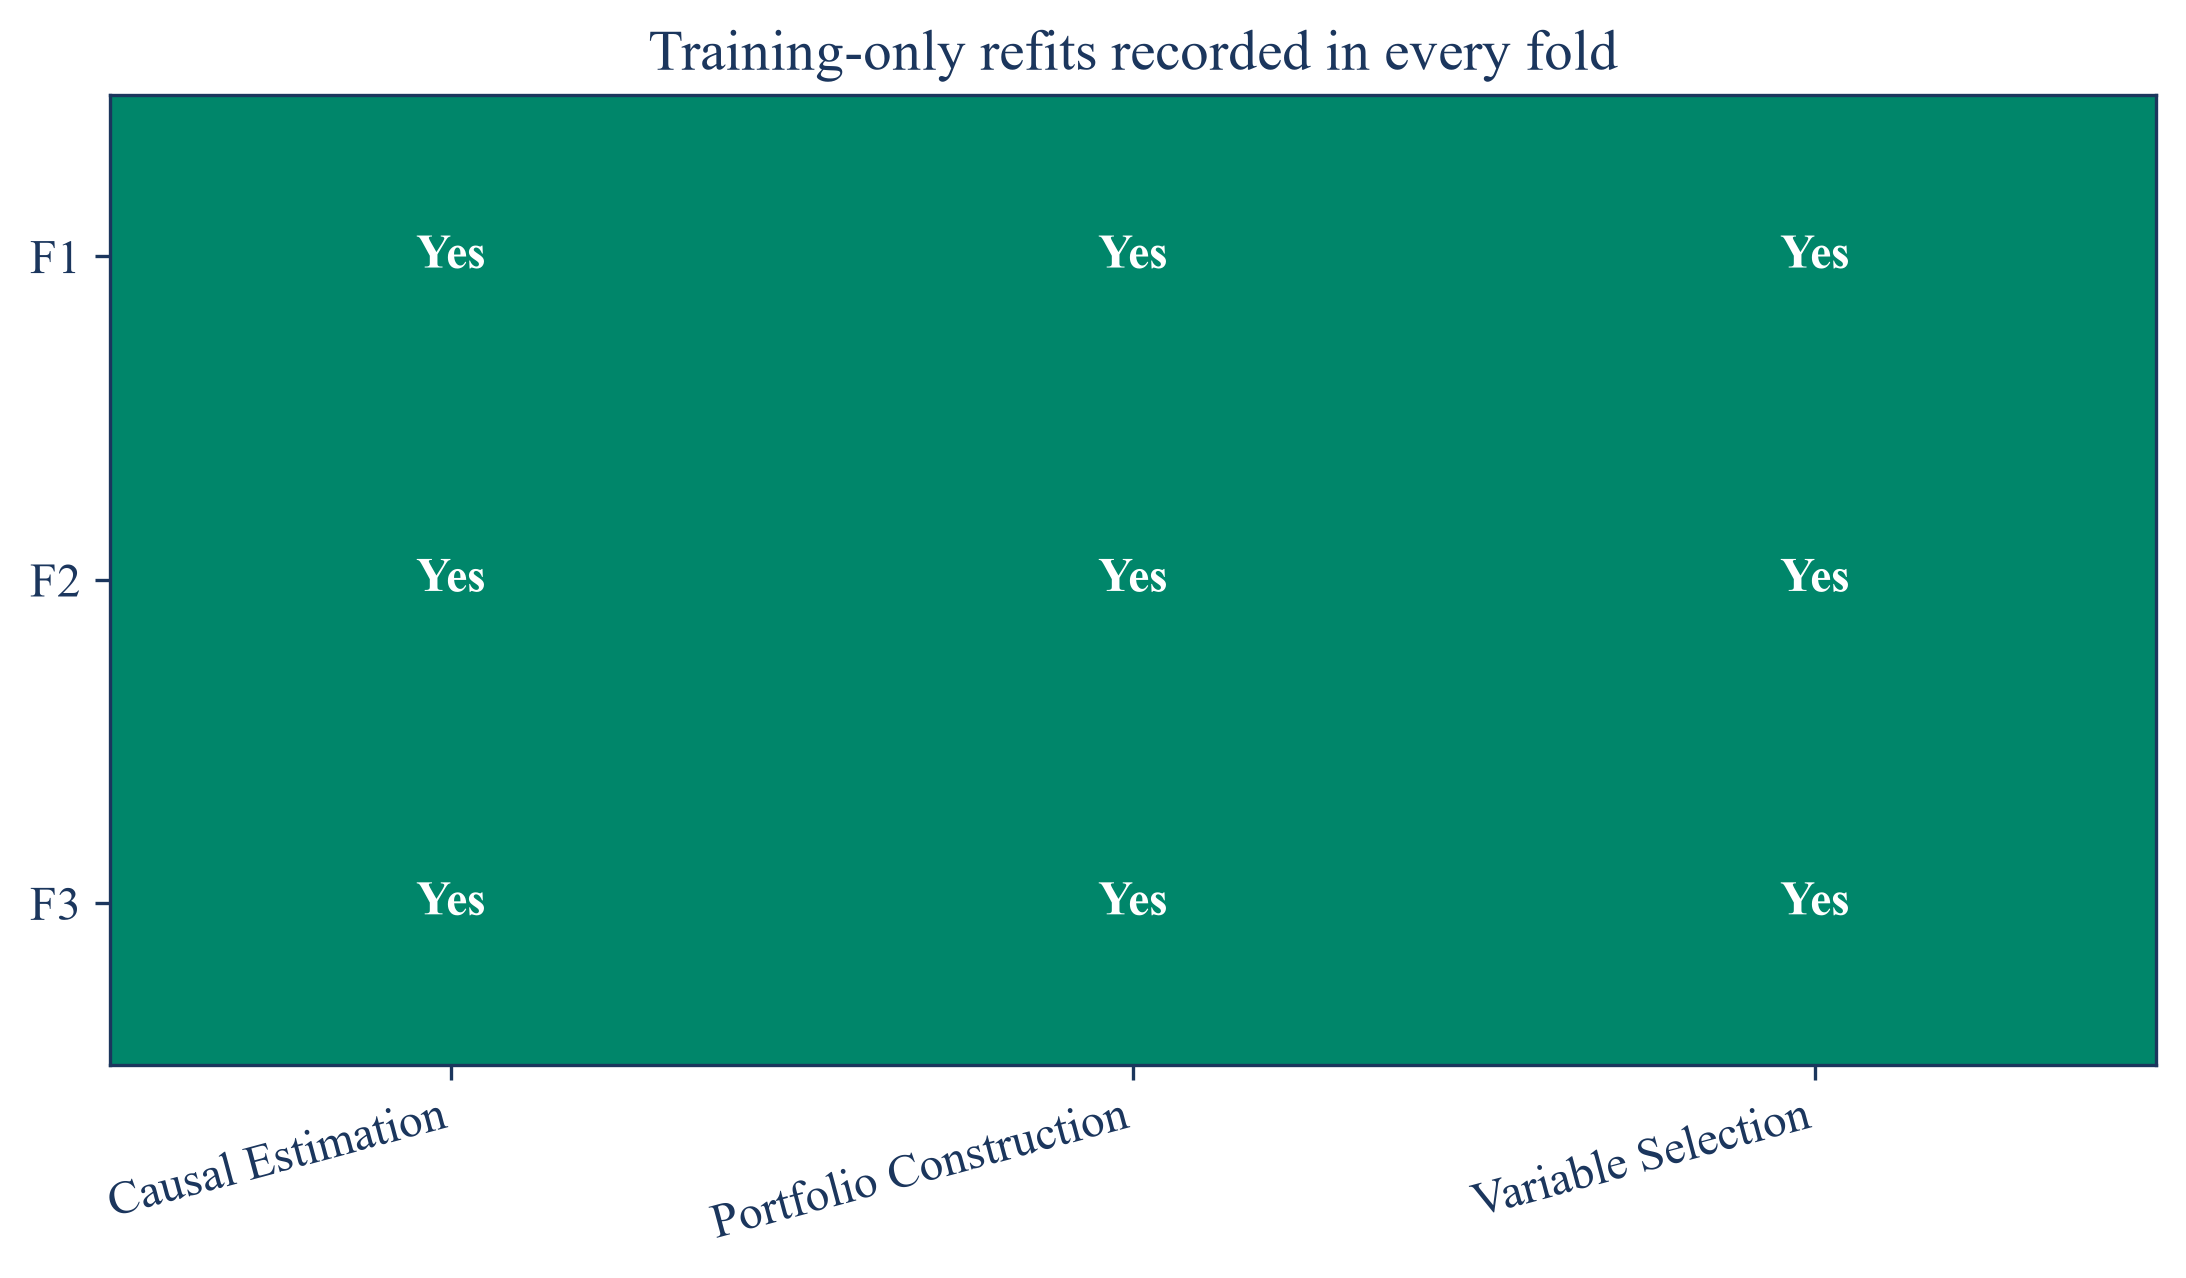

In [1]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display


def compact_float_format(number_format=None):
    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value


def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch(r"[+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?", rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return "0"
    if ("." in rendered or "e" in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered


def compact_numeric_text(text):
    pattern = r"(?<![0-9.eE])([+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])"
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)


def compact_table_latex(latex):
    return compact_numeric_text(latex)


def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + "</div>"


def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)

from pathlib import Path
from dataclasses import FrozenInstanceError, fields, replace
import inspect
import math
import re
import sys
import warnings
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
import numpy as np
import pandas as pd
from scipy.stats import norm, t as student_t
from IPython.display import Image

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from book_support import ensure_dataset
import hashlib
import io
import zipfile

DATA_URL = "https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/49_Industry_Portfolios_daily_CSV.zip"
DATA_DIR = ROOT / "data" / "public" / "ken_french"
DATA_PATH = ensure_dataset(ROOT, "french_49_industries")
EXPECTED_DATA_HASH = "8F394FE34BEA54D41B9AAFED410425EE8F8E252EDE3C71A7C1CD20BAB83040DE"
DATA_DIR.mkdir(parents=True, exist_ok=True)
assert DATA_PATH.is_file()
data_hash = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest().upper()
assert data_hash == EXPECTED_DATA_HASH
with zipfile.ZipFile(DATA_PATH) as archive:
    archive_name = archive.namelist()[0]
    public_lines = archive.read(archive_name).decode("latin1").splitlines()
header_row = next(index for index, line in enumerate(public_lines) if line.startswith(",Agric"))
end_row = next(index for index in range(header_row + 1, len(public_lines)) if not public_lines[index].strip())
raw = pd.read_csv(io.StringIO("\n".join(public_lines[header_row:end_row])))
raw = raw.rename(columns={raw.columns[0]: "Date"})
raw["Date"] = pd.to_datetime(raw["Date"].astype(str), format="%Y%m%d")
raw = raw.set_index("Date").replace([-99.99, -999.0], np.nan) / 100.0
industry_returns = raw.loc["2019-01-01":"2025-12-31"].dropna().copy()

from RiskLabAI.causal_factor_analysis.protocol import BacktestStage, CausalAdjustmentSetStage, CausalDiscoveryStage, CausalExplanatoryAndPredictivePowerStage, CausalFactorProtocolReport, CausalPortfolioConstructionStage, EventHorizon, FoldEvidence, MultipleTestingAdjustmentsStage, ValidationEvidence, VariableSelectionStage, validate_causal_factor_protocol

FIGURES = ROOT / "outputs" / "figures" / "10_causal_factor_protocol"
TABLES = ROOT / "outputs" / "tables" / "10_causal_factor_protocol"
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

palette = {"background": "#FFFFFF", "axes": "#FFFFFF", "text": "#1B365D", "cyan": "#0072B2", "amber": "#C76D00", "green": "#00866A", "rose": "#B83B3B", "violet": "#A03A78", "grid": "#D9DEE5", "muted": "#5C6670"}
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": palette["background"], "axes.facecolor": palette["axes"], "axes.edgecolor": palette["text"], "axes.labelcolor": palette["text"], "axes.titlecolor": palette["text"], "xtick.color": palette["text"], "ytick.color": palette["text"], "text.color": palette["text"], "grid.color": palette["grid"], "grid.linestyle": ":", "legend.facecolor": palette["axes"], "legend.edgecolor": palette["grid"], "savefig.facecolor": palette["background"]})

def display_float(value):
    if not np.isfinite(value):
        return str(value)
    nearest_integer = round(float(value))
    if np.isclose(value, nearest_integer, atol=1e-12):
        return str(int(nearest_integer))
    if abs(value) < 5e-13:
        return "0"
    return f"{value:.6f}".rstrip("0").rstrip(".")

pd.set_option("display.float_format", display_float)

def save_table(frame, stem, caption, label, float_format="%.6f", fit=True, position="tbp"):
    table_frame = frame.copy()
    for column in table_frame.columns:
        if pd.api.types.is_bool_dtype(table_frame[column]):
            table_frame[column] = table_frame[column].map({True: "Yes", False: "No"})
    table_frame.to_csv(TABLES / f"{stem}.csv", index=False)
    latex = compact_table_latex(table_frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position=position))
    if fit:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{adjustbox}{max width=\textwidth}" + "\n" + r"\begin{tabular}", 1).replace(r"\end{tabular}", r"\end{tabular}" + "\n" + r"\end{adjustbox}", 1)
    else:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{tabular}", 1)
    latex = re.sub(r"(?<![A-Za-z])(?:nan|NaN)(?![A-Za-z])", "Not available", latex)
    latex = re.sub(r"(?<![A-Za-z])inf(?![A-Za-z])", "No finite value", latex)
    (TABLES / f"{stem}.tex").write_text(latex, encoding="utf-8")

def save_figure(figure, stem):
    figure.savefig(FIGURES / f"{stem}.png", bbox_inches="tight", dpi=300)
    figure.savefig(FIGURES / f"{stem}.pdf", bbox_inches="tight")
    display(Image(filename=str(FIGURES / f"{stem}.png")))
    plt.close(figure)

def human_label(value):
    special = {"PC": "PC", "LINGAM": "LiNGAM", "R_SQUARED": "R squared", "MEAN_SQUARED_ERROR": "Mean squared error", "BENJAMINI_HOCHBERG": "Benjamini-Hochberg", "DEFLATED_SHARPE_RATIO": "Deflated Sharpe ratio"}
    return special.get(value, value.replace("_", " ").title())

def contract_case(name, stage, action):
    try:
        action()
        return {"Case": name, "Stage": stage, "Result": "Accepted", "Message": "Record satisfies the released checks", "Rejected": False}
    except Exception as error:
        message = str(error).replace("Causal factor protocol is invalid. ", "")
        message = message.split(". ", 1)[0].rstrip(".")
        return {"Case": name, "Stage": stage, "Result": "Rejected", "Message": message, "Rejected": True}

public_dates = industry_returns.index[:6]
observation_ids = tuple(f"event-{date:%Y-%m-%d}" for date in public_dates)

def make_horizons():
    intervals = ((0.0, 2.0), (1.0, 3.0), (4.0, 5.0), (6.0, 7.0), (8.0, 9.0), (10.0, 11.0))
    return tuple(EventHorizon(observation_id, start, end) for observation_id, (start, end) in zip(observation_ids, intervals))

def make_fold(fold_id, path_id, train_positions, test_positions, refit_id):
    train_ids = tuple(observation_ids[index] for index in train_positions)
    test_ids = tuple(observation_ids[index] for index in test_positions)
    return FoldEvidence(fold_id=fold_id, path_id=path_id, train_ids=train_ids, test_ids=test_ids, fit_ids=train_ids, prediction_ids=test_ids, refit_id=refit_id, refit_components=("VARIABLE_SELECTION", "CAUSAL_ESTIMATION", "PORTFOLIO_CONSTRUCTION"))

def temporal_validation(method_labels=("PURGED_CROSS_VALIDATION",), embargo=1.0):
    return ValidationEvidence(method_labels=method_labels, event_horizons=make_horizons(), folds=(make_fold("f1", "p1", (2, 3, 4, 5), (0, 1), "r1"), make_fold("f2", "p1", (0, 1, 4, 5), (2, 3), "r2"), make_fold("f3", "p1", (0, 1, 2, 3), (4, 5), "r3")), embargo=embargo)

def cpcv_validation():
    return ValidationEvidence(method_labels=("COMBINATORIAL_PURGED_CROSS_VALIDATION",), event_horizons=make_horizons(), folds=(make_fold("p1-f1", "p1", (2, 3, 4, 5), (0, 1), "p1-r1"), make_fold("p1-f2", "p1", (0, 1, 4, 5), (2, 3), "p1-r2"), make_fold("p1-f3", "p1", (0, 1, 2, 3), (4, 5), "p1-r3"), make_fold("p2-f1", "p2", (3, 4, 5), (0, 2), "p2-r1"), make_fold("p2-f2", "p2", (2, 3, 5), (1, 4), "p2-r2"), make_fold("p2-f3", "p2", (0, 1, 2), (3, 5), "p2-r3")), embargo=1.0)

def valid_protocol_report():
    trial_ids = ("strategy-a", "strategy-b", "strategy-c")
    family_id = "declared-family"
    selection_validation = temporal_validation()
    evaluation_validation = temporal_validation()
    return CausalFactorProtocolReport(trial_family_id=family_id, declared_trial_ids=trial_ids, variable_selection=VariableSelectionStage(purpose="RISK_PREMIA_HARVESTING", selected_variables=("X", "Z", "I", "M", "C", "D"), method_labels=("MUTUAL_INFORMATION", "SHAPLEY_VALUES", "MEAN_DECREASE_IMPURITY", "PERMUTATION_FEATURE_IMPORTANCE"), overlapping_returns=True, strong_time_dependence=True, validation=selection_validation), causal_discovery=CausalDiscoveryStage(method_labels=("PC", "ECONOMIC_REASONING", "DOMAIN_EXPERTISE", "OBSERVED_OUTCOMES"), graph_id="resolved-dag", graph_nodes=("X", "Y", "Z", "I", "M", "C", "D"), directed_edges=(("Z", "X"), ("Z", "Y"), ("I", "X"), ("X", "M"), ("M", "Y"), ("X", "Y"), ("X", "C"), ("Y", "C"), ("X", "D")), graph_kind="DAG", ambiguous_edges=(), assumptions=("The recorded variables are sufficient for the target effect.", "Directions use time order and economic restrictions.")), causal_adjustment_set=CausalAdjustmentSetStage(treatment="X", outcome="Y", method_label="BACKDOOR_ADJUSTMENT", identified=True, admissible_adjustment_sets=(("Z",),), selected_adjustment_set=("Z",), confounders=("Z",), descendants=("M", "C", "D"), mediators=("M",), colliders=("C",), instruments=("I",), control_justifications=(("Z", "Common cause of factor and return."),), open_backdoor_paths=()), causal_explanatory_and_predictive_power=CausalExplanatoryAndPredictivePowerStage(task_types=("RETURN_SIZE",), estimator_label="fold-refit causal regression", explanatory_metric_labels=("R_SQUARED",), predictive_metric_labels=("MEAN_SQUARED_ERROR", "SPEARMAN_CORRELATION"), explanatory_evidence_id="explanatory-evidence", predictive_evidence_id="predictive-evidence", naive_benchmark_id="training-mean-benchmark", validation=evaluation_validation), causal_portfolio_construction=CausalPortfolioConstructionStage(method_labels=("POSITION_SIZING", "EXPOSURE_CONTROL", "ECONOMIC_RATIONALE", "FRAGILITY_STRESS_TEST", "TRANSACTION_COST_OPTIMIZATION", "TRANSFER_COEFFICIENT"), causal_exposures=("X",), controlled_unintended_exposures=("C", "D"), cost_model_id="cost-record", constraint_set_id="constraint-record", economic_rationale="Positions target the supplied X to Y effect.", fragility_scenarios=("weaken X to Y", "perturb Z to X"), transfer_coefficient=0.82), backtest=BacktestStage(method_labels=("COMBINATORIAL_PURGED_CROSS_VALIDATION",), trial_family_id=family_id, declared_trial_ids=trial_ids, validation=cpcv_validation()), multiple_testing_adjustments=MultipleTestingAdjustmentsStage(method_labels=("HOLM", "DEFLATED_SHARPE_RATIO"), trial_family_id=family_id, declared_trial_ids=trial_ids, family_partitions=(("primary", ("strategy-a", "strategy-b")), ("robustness", ("strategy-c",))), alpha=0.05, backtests_independent=False, p_value_estimator="estimator accounting for time dependence", time_dependence_model="purged temporal folds", p_value_inputs_assume_independence=False, sharpe_variance=0.04, effective_trials=2.0, sample_length=252, skewness=0.1, kurtosis=3.2, selection_bias_evidence_id="selection-bias-evidence"))

def public_trial_returns():
    base = industry_returns.iloc[:, :12].mean(axis=1).rename("Market basket")
    direction = np.sign(base.shift(1)).replace(0.0, 1.0)
    trials = pd.DataFrame({"Strategy A": base, "Strategy B": direction * base, "Strategy C": -direction * base})
    return trials.loc["2023-01-01":"2025-12-31"].dropna()

def draw_causal_graph(edges, stem, title):
    positions = {"I": (-1.7, 0.7), "Z": (-1.7, -0.7), "X": (-0.5, 0.0), "M": (0.5, 0.8), "Y": (1.6, 0.0), "C": (0.5, -0.8), "D": (-0.4, -1.25)}
    colors = {"I": palette["violet"], "Z": palette["amber"], "X": palette["cyan"], "M": palette["green"], "Y": palette["rose"], "C": palette["muted"], "D": palette["text"]}
    figure, axis = plt.subplots(figsize=(9.0, 5.2))
    for source_node, target_node in edges:
        start = positions[source_node]
        end = positions[target_node]
        axis.annotate("", xy=end, xytext=start, arrowprops={"arrowstyle": "->", "color": palette["grid"], "lw": 1.8, "shrinkA": 18, "shrinkB": 18})
    for node, (x_value, y_value) in positions.items():
        axis.scatter([x_value], [y_value], s=900, color=colors[node], edgecolor=palette["text"], linewidth=1.2, zorder=3)
        axis.text(x_value, y_value, node, ha="center", va="center", color=palette["background"], fontsize=12, fontweight="bold", zorder=4)
    axis.set_xlim(-2.2, 2.1)
    axis.set_ylim(-1.65, 1.3)
    axis.set_title(title)
    axis.axis("off")
    save_figure(figure, stem)

report = validate_causal_factor_protocol(valid_protocol_report())
validation = report.causal_explanatory_and_predictive_power.validation
fold_rows = []
for fold in validation.folds:
    fold_rows.append({"Fold": fold.fold_id.upper(), "Training observations": len(fold.train_ids), "Test observations": len(fold.test_ids), "Fit equals training": set(fold.fit_ids) == set(fold.train_ids), "Predictions equal test": set(fold.prediction_ids) == set(fold.test_ids), "Refit record": fold.refit_id.upper(), "Refitted parts": len(fold.refit_components)})
fold_evidence = pd.DataFrame(fold_rows)
save_table(fold_evidence, "protocol_fold_evidence", "Foldwise fitting and prediction evidence.", "tab:chapter28-fold-evidence")
display(fold_evidence)

component_rows = []
for fold in validation.folds:
    for component in ("VARIABLE_SELECTION", "CAUSAL_ESTIMATION", "PORTFOLIO_CONSTRUCTION"):
        component_rows.append({"Fold": fold.fold_id.upper(), "Part": human_label(component), "Recorded": component in fold.refit_components})
component_table = pd.DataFrame(component_rows)
save_table(component_table, "protocol_fold_refits", "Required training-only refits in every fold.", "tab:chapter28-fold-refits")
display(component_table)

refit_matrix = component_table.pivot(index="Fold", columns="Part", values="Recorded").astype(int)
figure, axis = plt.subplots(figsize=(8.8, 4.2))
axis.imshow(refit_matrix, cmap=matplotlib.colors.ListedColormap([palette["rose"], palette["green"]]), vmin=0, vmax=1, aspect="auto")
axis.set_xticks(range(refit_matrix.shape[1]), refit_matrix.columns, rotation=15, ha="right")
axis.set_yticks(range(refit_matrix.shape[0]), refit_matrix.index)
axis.set_title("Training-only refits recorded in every fold")
for row in range(refit_matrix.shape[0]):
    for column in range(refit_matrix.shape[1]):
        axis.text(column, row, "Yes" if refit_matrix.iloc[row, column] else "No", ha="center", va="center", color=palette["background"], fontweight="bold")
save_figure(figure, "protocol_fold_refits")
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": "#FFFFFF", "axes.facecolor": "#FFFFFF", "axes.edgecolor": "#5C6670", "axes.labelcolor": "#1B365D", "axes.titlecolor": "#1B365D", "axes.titleweight": "bold", "xtick.color": "#5C6670", "ytick.color": "#5C6670", "text.color": "#1B365D", "grid.color": "#D9DEE5", "grid.linestyle": ":", "grid.linewidth": 0.8, "legend.facecolor": "#FFFFFF", "legend.edgecolor": "#D9DEE5", "legend.framealpha": 0.96, "savefig.facecolor": "#FFFFFF", "savefig.transparent": False, "savefig.dpi": 300, "pdf.fonttype": 42, "ps.fonttype": 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == "3.2.0"


## Keeping explanation separate from prediction

Return-size evidence can use separate explanatory and predictive measures:

$$
R^2_{\mathrm{train}}=1-\frac{\sum_{i\in\mathcal T_k}(y_i-\widehat y_i)^2}{\sum_{i\in\mathcal T_k}(y_i-\bar y_{\mathcal T_k})^2},
\qquad
\operatorname{MSE}_{\mathrm{test}}=\frac{1}{|\mathcal V_k|}\sum_{i\in\mathcal V_k}(y_i-\widehat y_i)^2.
$$

Here, $R^2_{\mathrm{train}}$ is explanatory fit on training observations; $\operatorname{MSE}_{\mathrm{test}}$ is predictive error on held-out observations; $y_i$ is the observed return; $\widehat y_i$ is its fitted or predicted value; $\bar y_{\mathcal T_k}$ is the training mean; $\mathcal T_k$ and $\mathcal V_k$ are training and test memberships; and $|\mathcal V_k|$ is the number of test observations.

,Evidence aspect,Measure,Evidence record
0,Explanatory,R squared,explanatory-evidence
1,Predictive,Mean squared error,predictive-evidence
2,Predictive,Spearman Correlation,predictive-evidence


,Fold,Training observations,Test observations,Training R squared,Test mean squared error,Simple-rule mean squared error,Test Spearman correlation
0,2023,1007,250,0.035143,0.000225,0.000217,-0.002458
1,2024,1257,252,0.027128,0.000275,0.000277,0.025669
2,2025,1509,250,0.024606,0.000226,0.000225,0.086756


,Data item,Value
0,Archive,Kenneth R. French 49 Industry Portfolios daily...
1,SHA256,8F394FE34BEA54D41B9AAFED410425EE8F8E252EDE3C71...
2,Date range,2019-01-02 to 2025-12-31
3,Target series,Agric
4,Lagged public predictors,3
5,Held-out prediction years,3


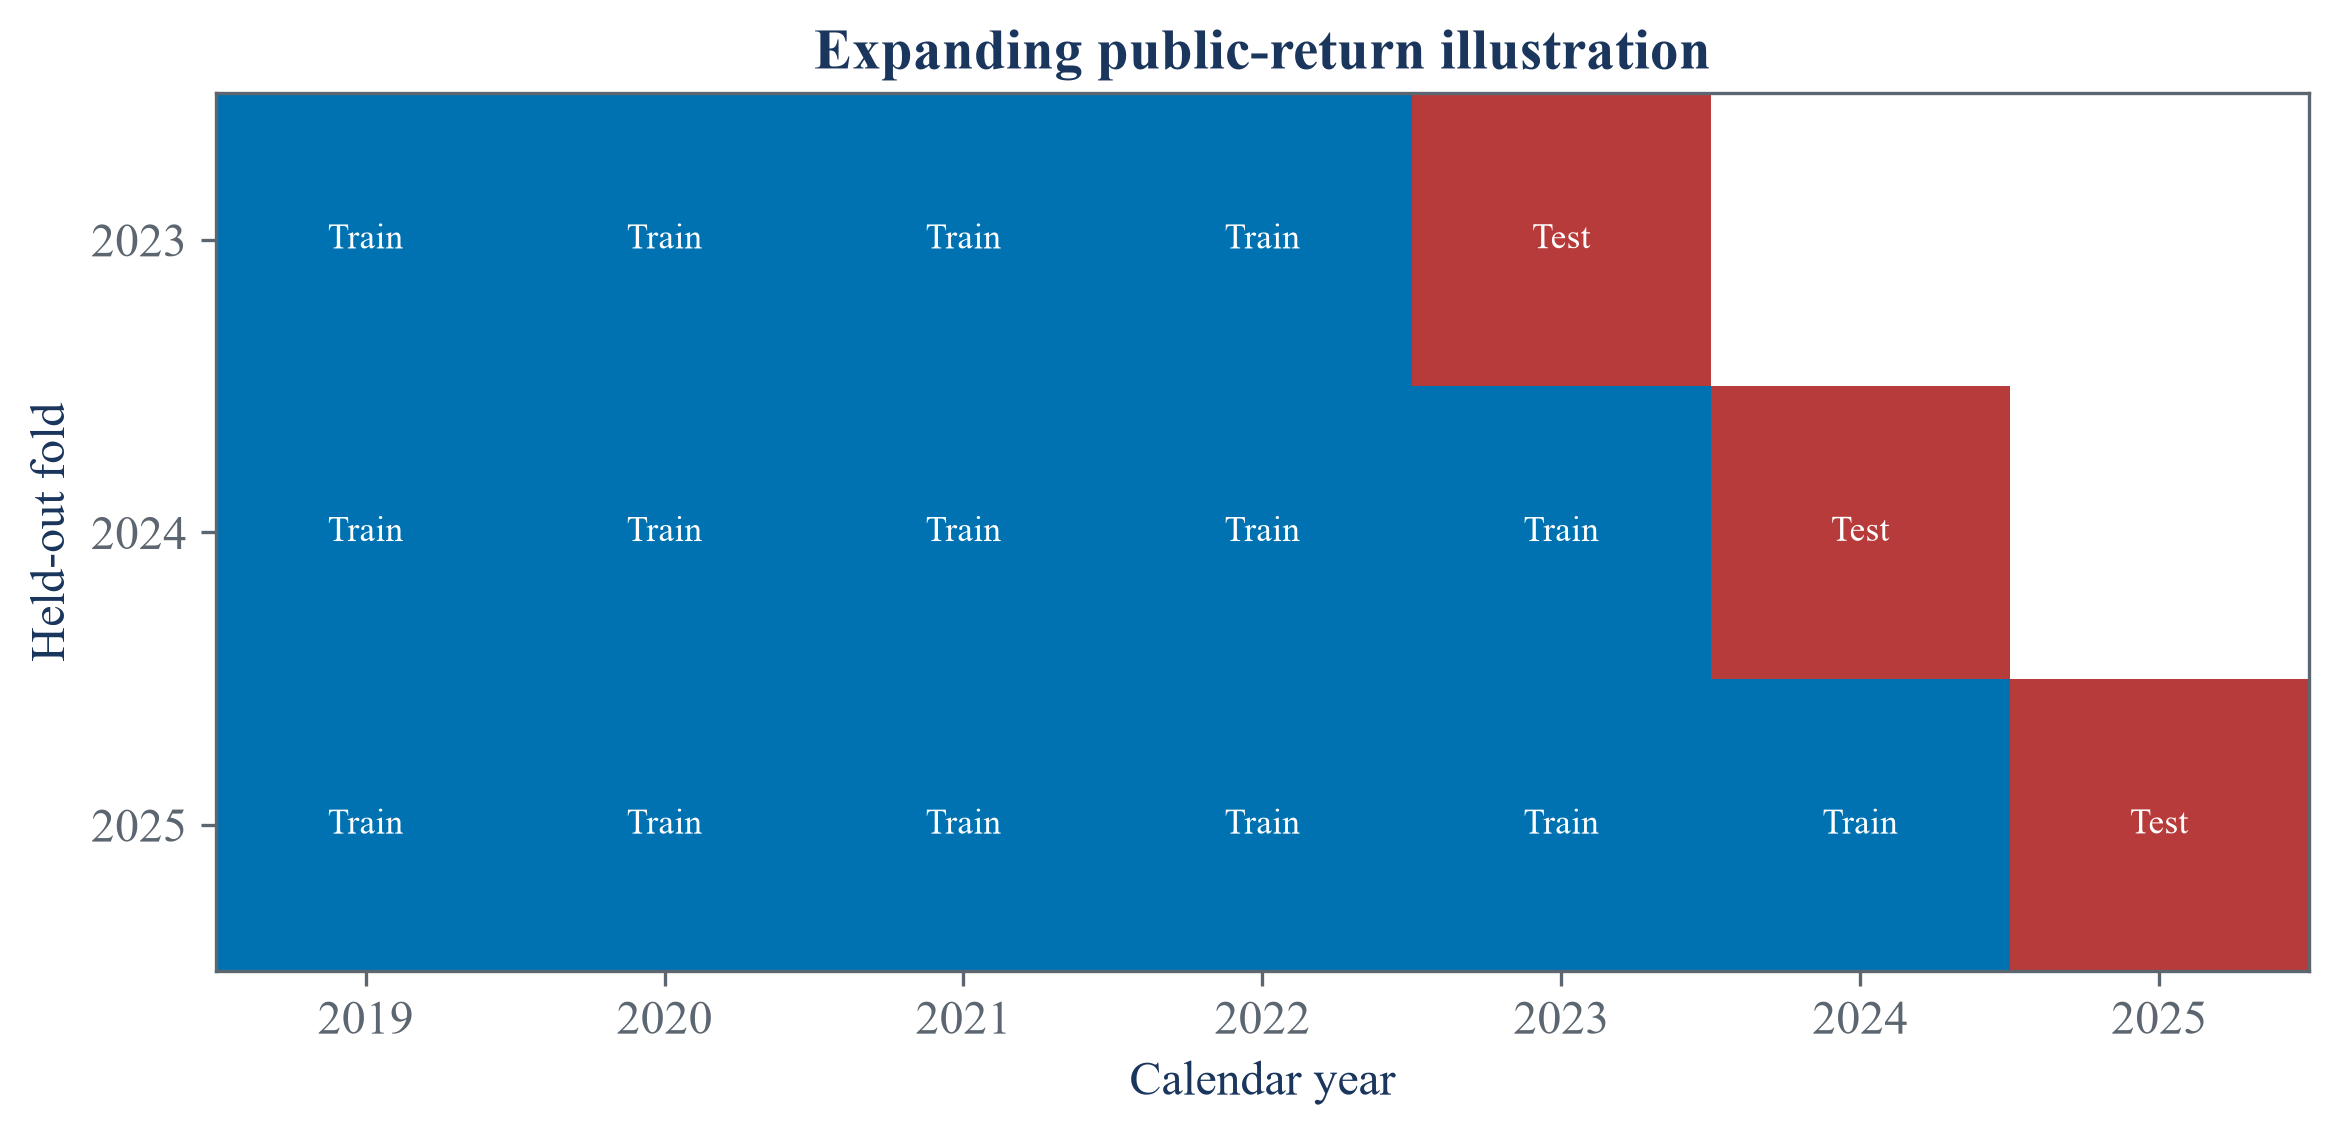

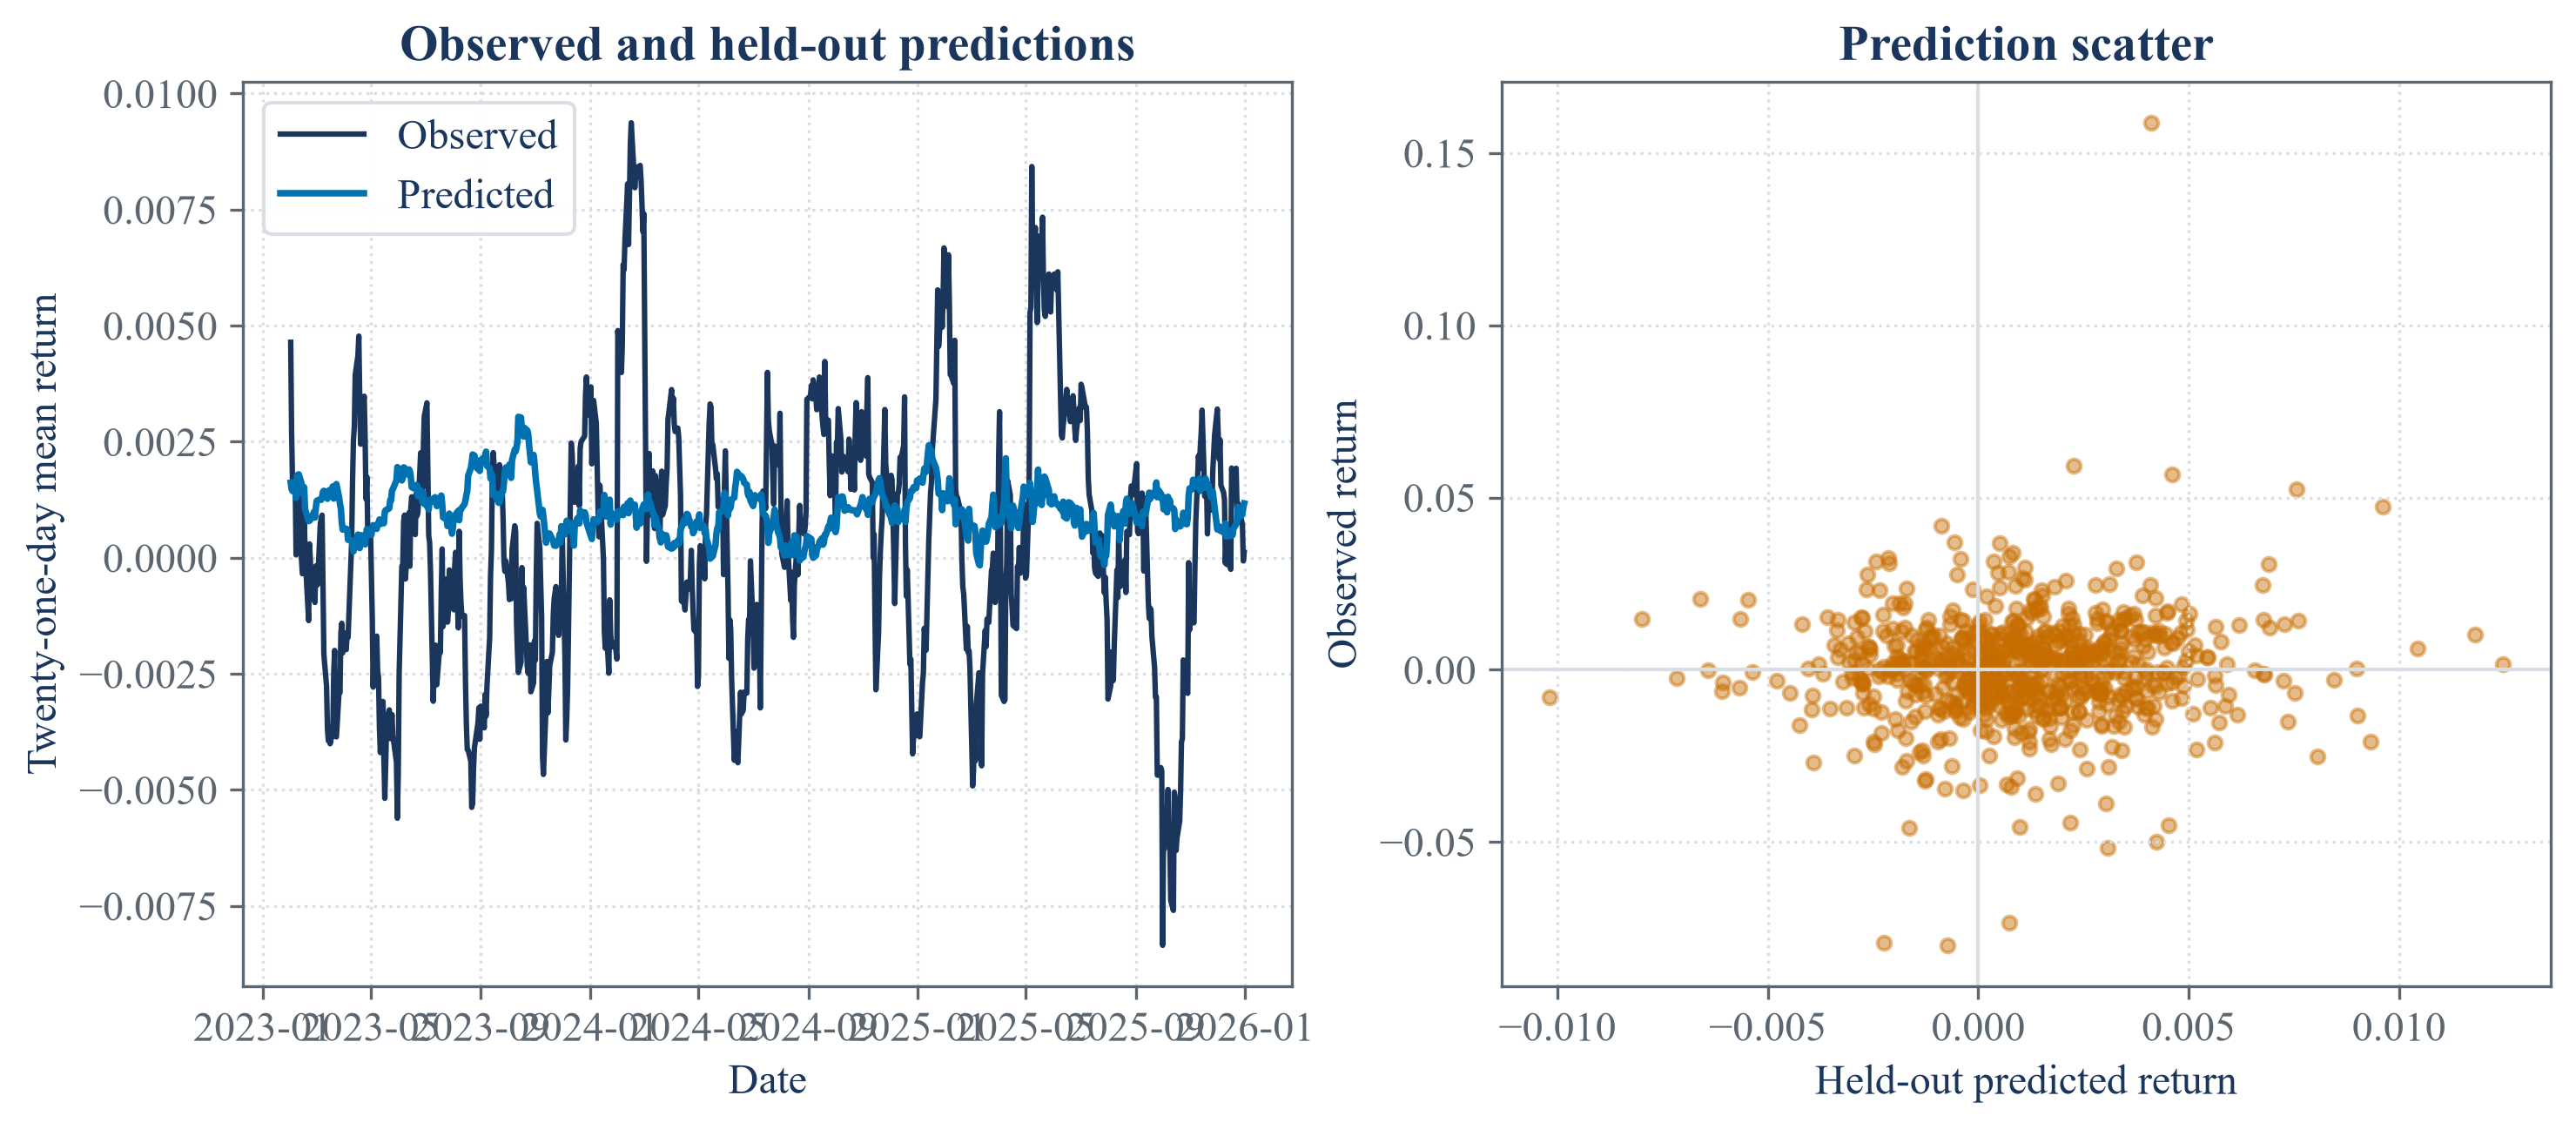

In [2]:
stage4 = report.causal_explanatory_and_predictive_power
metric_rows = []
for aspect, labels, evidence_id in [("Explanatory", stage4.explanatory_metric_labels, stage4.explanatory_evidence_id), ("Predictive", stage4.predictive_metric_labels, stage4.predictive_evidence_id)]:
    for label in labels:
        metric_rows.append({"Evidence aspect": aspect, "Measure": human_label(label), "Evidence record": evidence_id})
metric_table = pd.DataFrame(metric_rows)
save_table(metric_table, "protocol_stage4_metrics", "Separate explanatory and predictive evidence records.", "tab:chapter28-stage4-metrics")
display(metric_table)

public_panel = industry_returns.iloc[:, :6].copy()
target_name = public_panel.columns[0]
feature_names = list(public_panel.columns[1:4])
design = public_panel[feature_names].shift(1).copy()
design.columns = [f"Lagged {value}" for value in feature_names]
design["Target"] = public_panel[target_name]
design = design.dropna()
public_fold_specs = [("2023", "2022-12-31", "2023-01-01", "2023-12-31"), ("2024", "2023-12-31", "2024-01-01", "2024-12-31"), ("2025", "2024-12-31", "2025-01-01", "2025-12-31")]
public_metric_rows = []
prediction_parts = []
for fold_name, train_end, test_start, test_end in public_fold_specs:
    train = design.loc[:train_end]
    test = design.loc[test_start:test_end]
    x_train = np.column_stack([np.ones(len(train)), train.drop(columns="Target").to_numpy()])
    x_test = np.column_stack([np.ones(len(test)), test.drop(columns="Target").to_numpy()])
    y_train = train["Target"].to_numpy()
    y_test = test["Target"].to_numpy()
    coefficients = np.linalg.lstsq(x_train, y_train, rcond=None)[0]
    fitted = x_train @ coefficients
    predicted = x_test @ coefficients
    benchmark = np.repeat(y_train.mean(), len(test))
    train_r_squared = 1.0 - np.sum((y_train - fitted) ** 2) / np.sum((y_train - y_train.mean()) ** 2)
    test_mse = np.mean((y_test - predicted) ** 2)
    benchmark_mse = np.mean((y_test - benchmark) ** 2)
    spearman = pd.Series(y_test).corr(pd.Series(predicted), method="spearman")
    public_metric_rows.append({"Fold": fold_name, "Training observations": len(train), "Test observations": len(test), "Training R squared": train_r_squared, "Test mean squared error": test_mse, "Simple-rule mean squared error": benchmark_mse, "Test Spearman correlation": spearman})
    prediction_parts.append(pd.DataFrame({"Date": test.index, "Fold": fold_name, "Observed return": y_test, "Predicted return": predicted, "Simple-rule prediction": benchmark}))
public_metrics = pd.DataFrame(public_metric_rows)
prediction_frame = pd.concat(prediction_parts, ignore_index=True).sort_values("Date").reset_index(drop=True)
save_table(public_metrics, "protocol_public_fold_metrics", "Foldwise public-return measures with a training-mean comparison rule.", "tab:chapter28-public-fold-metrics")
display(public_metrics)

data_table = pd.DataFrame([{"Data item": "Archive", "Value": "Kenneth R. French 49 Industry Portfolios daily returns"}, {"Data item": "SHA256", "Value": data_hash}, {"Data item": "Date range", "Value": f"{industry_returns.index.min():%Y-%m-%d} to {industry_returns.index.max():%Y-%m-%d}"}, {"Data item": "Target series", "Value": target_name}, {"Data item": "Lagged public predictors", "Value": len(feature_names)}, {"Data item": "Held-out prediction years", "Value": len(public_fold_specs)}])
save_table(data_table, "protocol_public_data", "Public-return source and foldwise illustration.", "tab:chapter28-public-data")
display(data_table)

year_matrix = np.zeros((len(public_fold_specs), 7))
year_labels = list(range(2019, 2026))
for row, (fold_name, train_end, test_start, test_end) in enumerate(public_fold_specs):
    for column, year in enumerate(year_labels):
        if year <= int(train_end[:4]):
            year_matrix[row, column] = 1
        if year == int(test_start[:4]):
            year_matrix[row, column] = -1
figure, axis = plt.subplots(figsize=(9.0, 3.8))
axis.imshow(year_matrix, cmap=matplotlib.colors.ListedColormap([palette["rose"], palette["axes"], palette["cyan"]]), vmin=-1, vmax=1, aspect="auto")
axis.set_xticks(range(len(year_labels)), year_labels)
axis.set_yticks(range(len(public_fold_specs)), [value[0] for value in public_fold_specs])
axis.set_xlabel("Calendar year")
axis.set_ylabel("Held-out fold")
axis.set_title("Expanding public-return illustration")
for row in range(year_matrix.shape[0]):
    for column in range(year_matrix.shape[1]):
        label = "Test" if year_matrix[row, column] == -1 else "Train" if year_matrix[row, column] == 1 else ""
        if label:
            axis.text(column, row, label, ha="center", va="center", fontsize=8.5, color=palette["background"])
save_figure(figure, "protocol_public_folds")

figure, axes = plt.subplots(1, 2, figsize=(11.4, 4.5))
axes[0].plot(prediction_frame["Date"], prediction_frame["Observed return"].rolling(21).mean(), color=palette["text"], linewidth=1.5, label="Observed")
axes[0].plot(prediction_frame["Date"], prediction_frame["Predicted return"].rolling(21).mean(), color=palette["cyan"], linewidth=1.8, label="Predicted")
axes[0].set_xlabel("Date")
axes[0].set_ylabel("Twenty-one-day mean return")
axes[0].set_title("Observed and held-out predictions")
axes[0].legend()
axes[0].grid(True)
axes[1].scatter(prediction_frame["Predicted return"], prediction_frame["Observed return"], color=palette["amber"], alpha=0.45, s=14)
axes[1].axhline(0.0, color=palette["grid"], linewidth=1.0)
axes[1].axvline(0.0, color=palette["grid"], linewidth=1.0)
axes[1].set_xlabel("Held-out predicted return")
axes[1].set_ylabel("Observed return")
axes[1].set_title("Prediction scatter")
axes[1].grid(True)
save_figure(figure, "protocol_public_predictions")

## Carrying causal estimates into portfolio decisions

The transfer coefficient compares intended and achieved exposures through their correlation:

$$
\operatorname{TC}=\frac{\sum_{j=1}^{J}(a_j-\bar a)(b_j-\bar b)}{\sqrt{\sum_{j=1}^{J}(a_j-\bar a)^2}\sqrt{\sum_{j=1}^{J}(b_j-\bar b)^2}}.
$$

Here, $\operatorname{TC}$ is the transfer coefficient; $a_j$ is the intended exposure for asset $j$; $b_j$ is the achieved exposure; $\bar a$ and $\bar b$ are their cross-asset means; and $J$ is the number of assets.

,Required consideration,Recorded evidence
0,Position Sizing,Causal exposure X drives position size
1,Exposure Control,Collider C and descendant D are neutralized
2,Economic Rationale,Positions target the supplied X to Y effect.
3,Fragility Stress Test,weaken X to Y; perturb Z to X
4,Transaction Cost Optimization,cost-record
5,Transfer Coefficient,0.82


,Path,Annual mean return,Annual volatility,Annual Sharpe ratio,Total return,Average daily turnover
0,Gross,0.162225,0.245561,0.660629,0.485138,0.868351
1,After transaction costs,0.052813,0.24548,0.215141,0.071566,0.868351


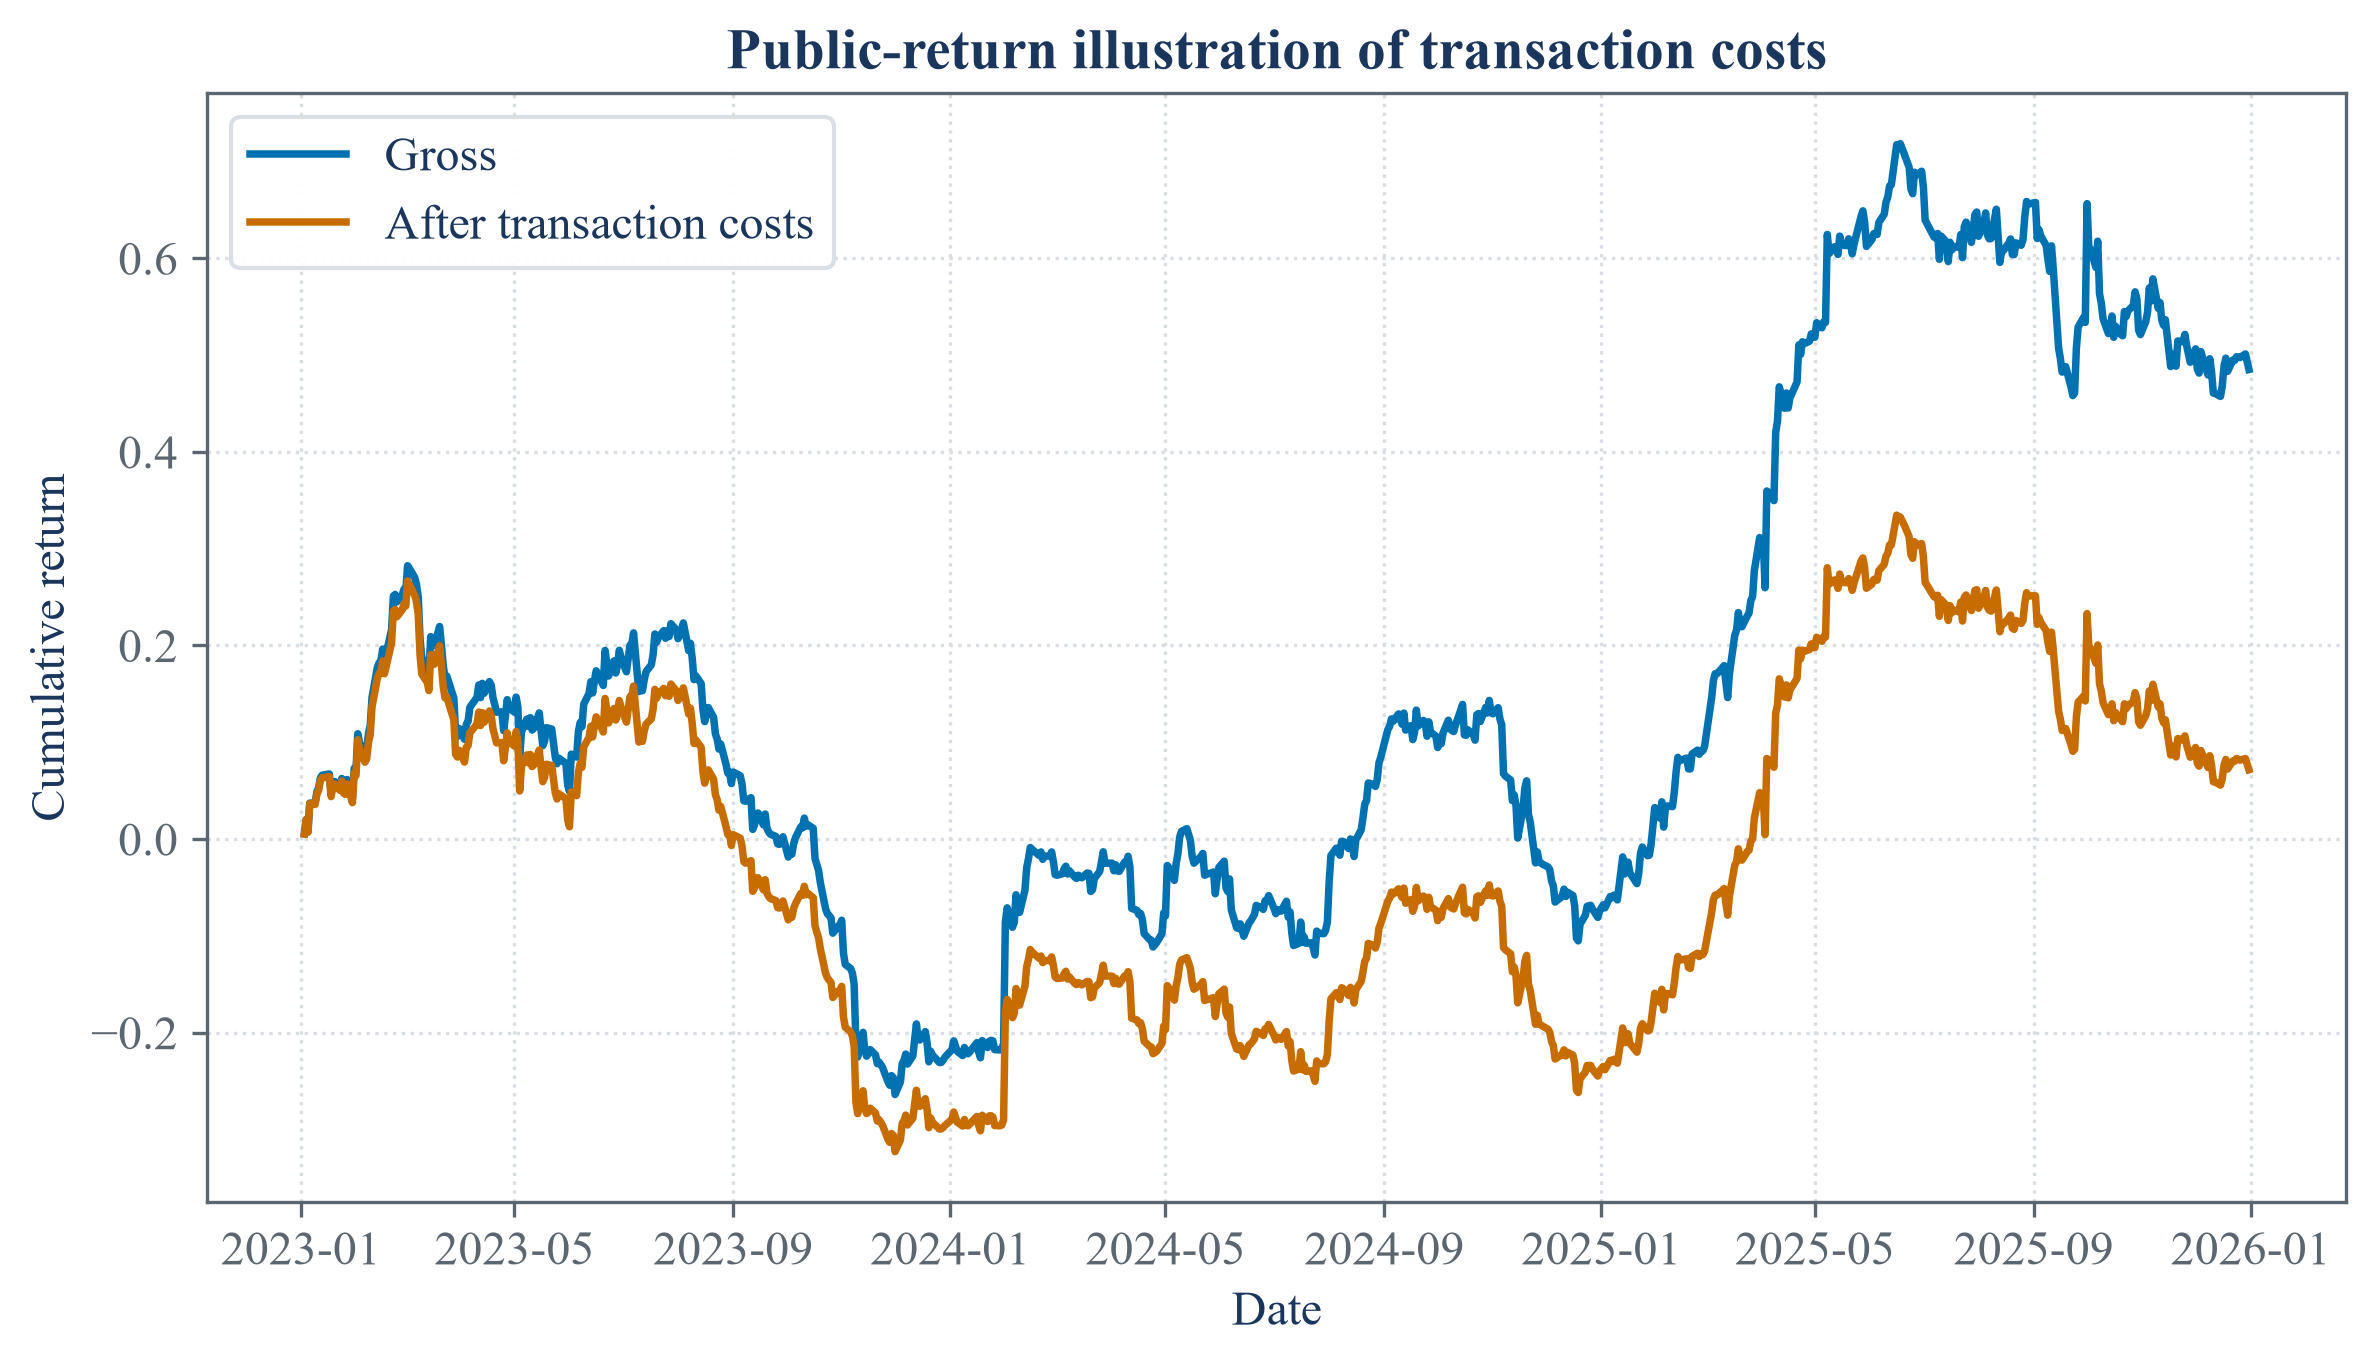

,Industry,Illustrative weight,Annual mean return
0,Agric,0.019054,0.103581
1,Food,-0.157169,-0.065949
2,Soda,0.00627,0.091283
3,Beer,-0.151804,-0.060788
4,Smoke,0.125401,0.205889
5,Toys,0.018322,0.102878
6,Fun,0.210534,0.287789
7,Books,0.074265,0.156696
8,Hshld,-0.081789,0.006568
9,Clths,-0.10464,-0.015415


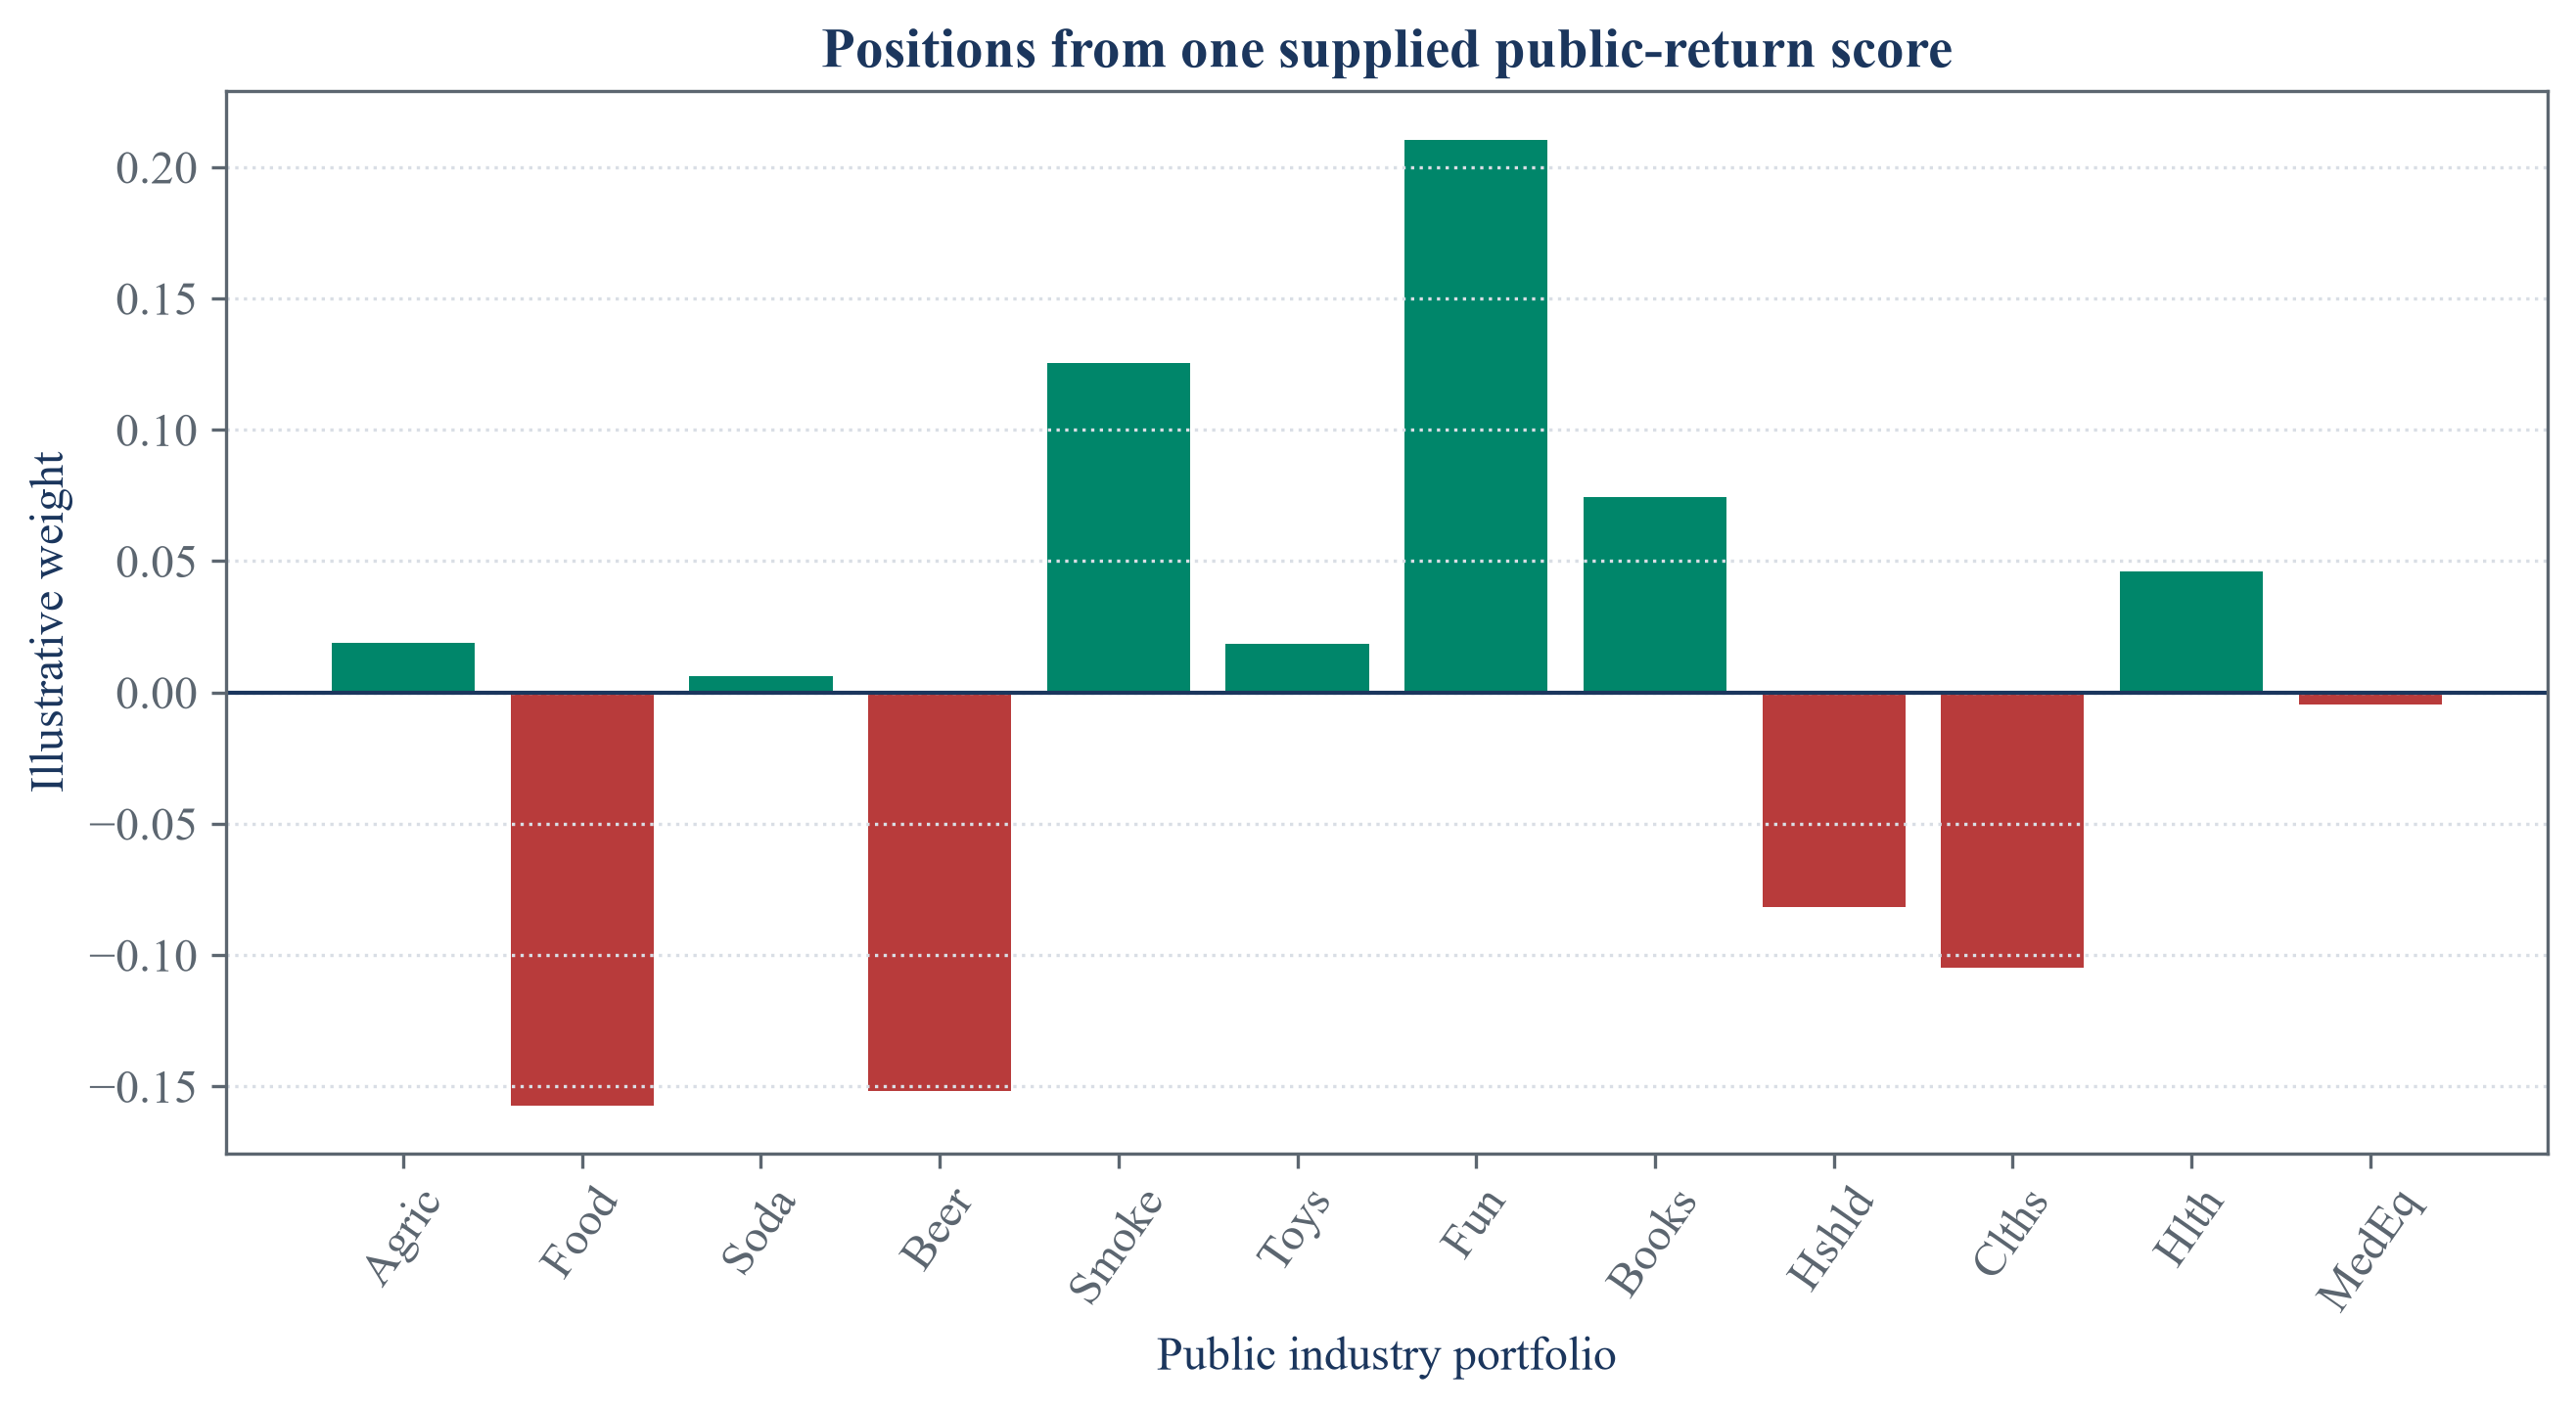

,Disturbance scale,Transfer coefficient,Exposure root mean squared error
0,0,1,0
1,0.05,0.997933,0.049726
2,0.1,0.985452,0.128761
3,0.2,0.939124,0.228835
4,0.4,0.725372,0.4742
5,0.8,0.571225,0.685252


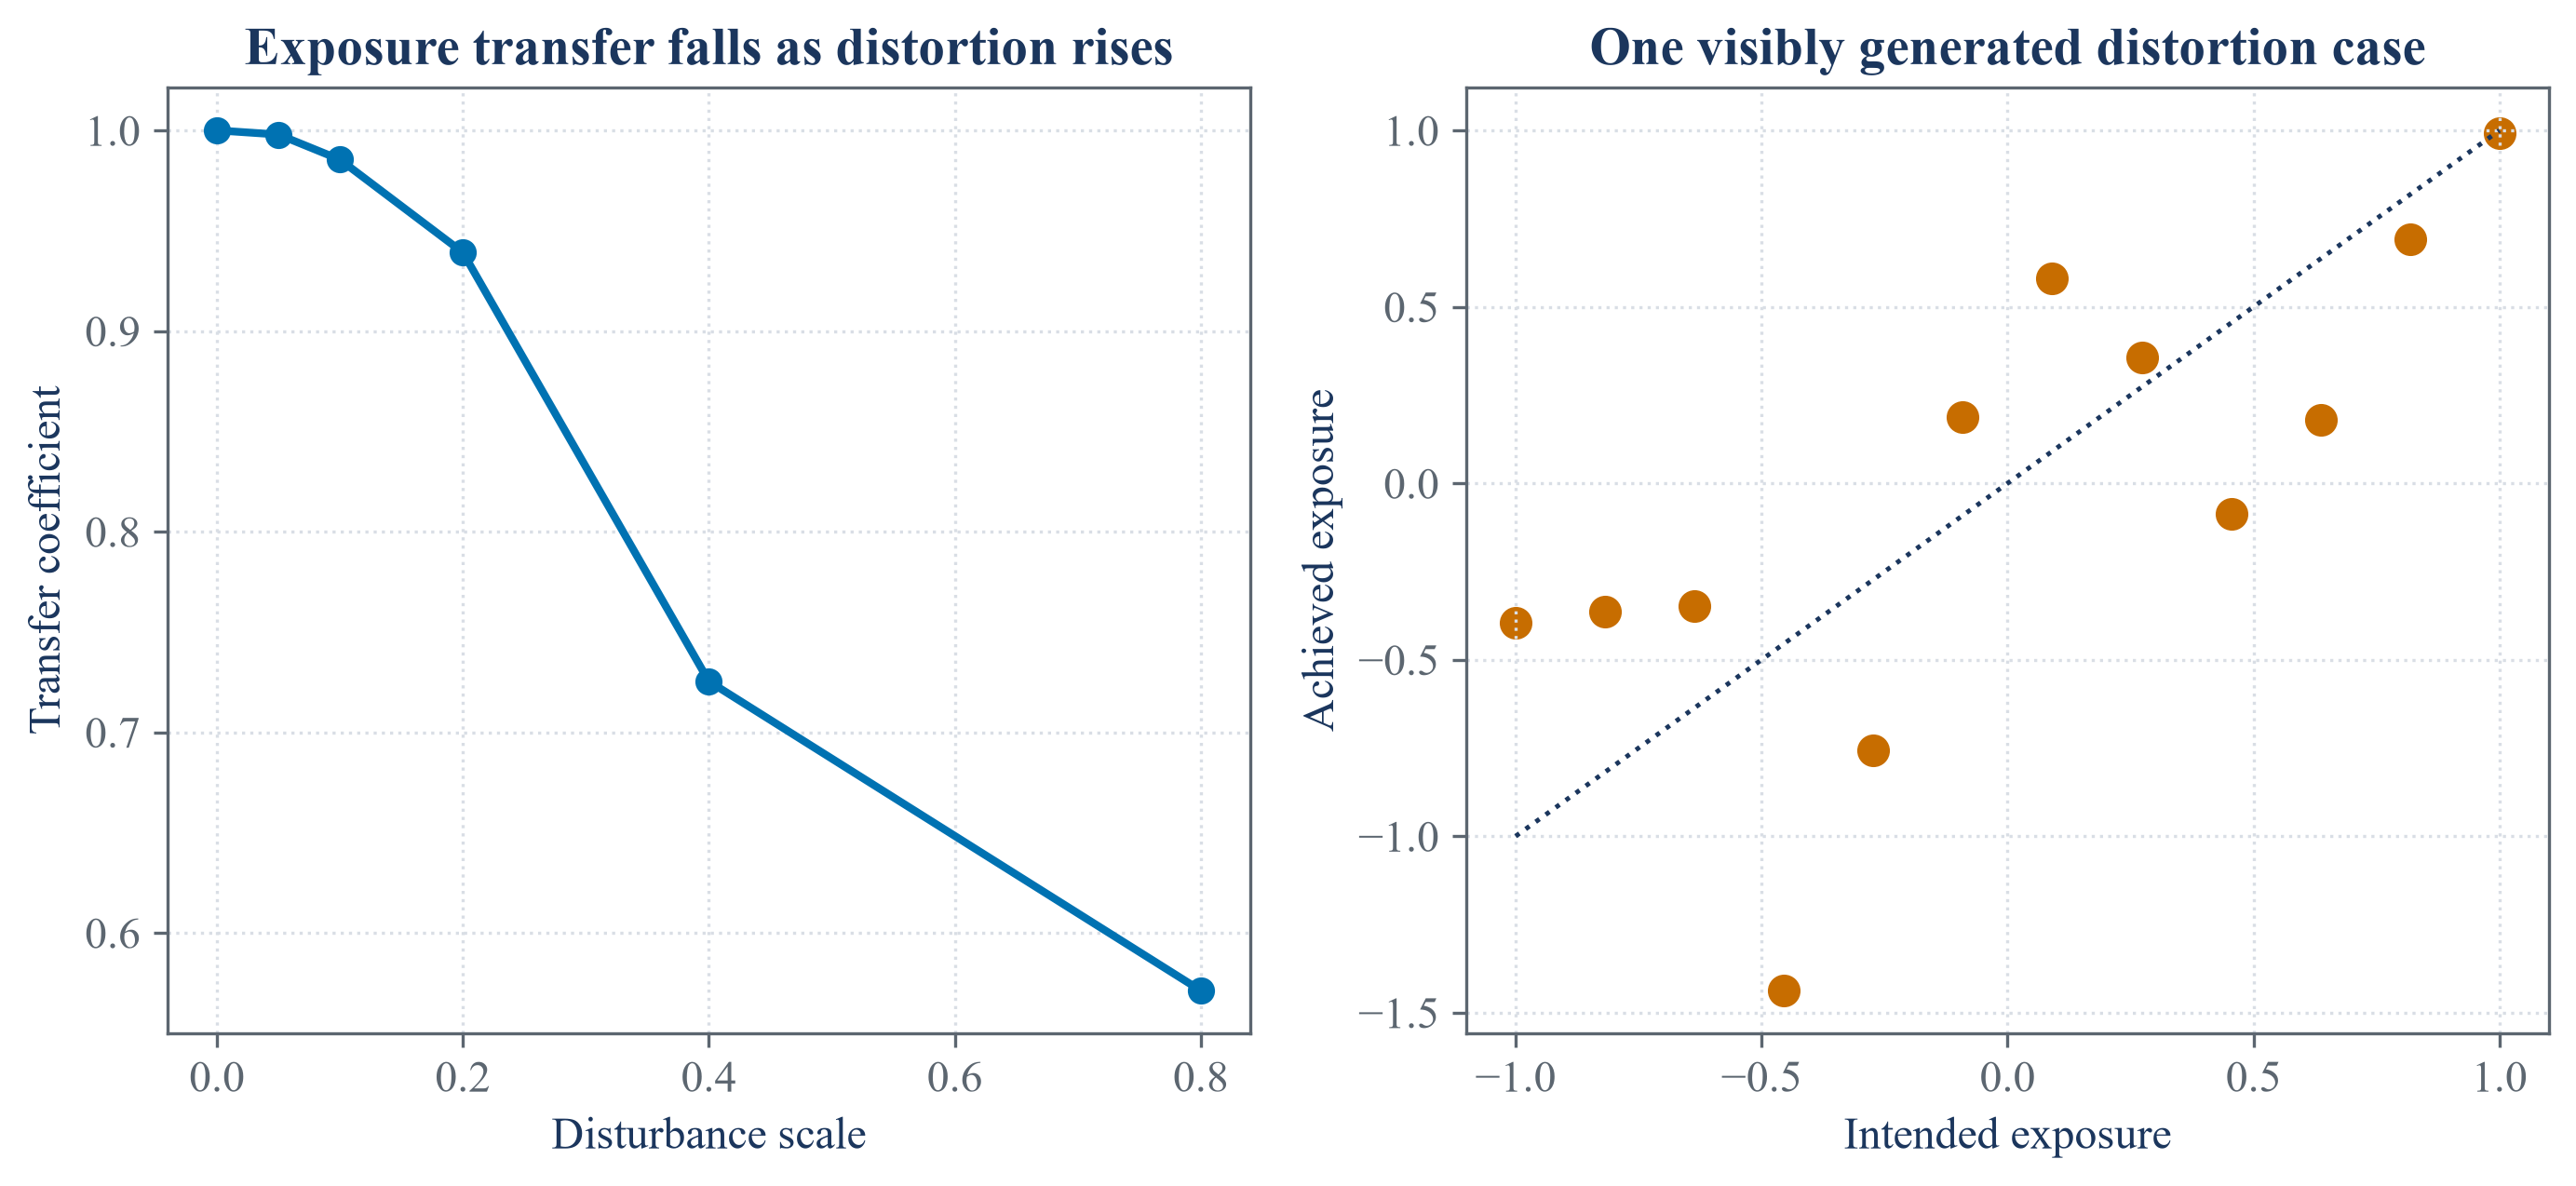

In [3]:
portfolio = report.causal_portfolio_construction
portfolio_rows = [{"Required consideration": human_label(value), "Recorded evidence": {"POSITION_SIZING": "Causal exposure X drives position size", "EXPOSURE_CONTROL": "Collider C and descendant D are neutralized", "ECONOMIC_RATIONALE": portfolio.economic_rationale, "FRAGILITY_STRESS_TEST": "; ".join(portfolio.fragility_scenarios), "TRANSACTION_COST_OPTIMIZATION": portfolio.cost_model_id, "TRANSFER_COEFFICIENT": display_float(portfolio.transfer_coefficient)}[value]} for value in portfolio.method_labels]
portfolio_table = pd.DataFrame(portfolio_rows)
save_table(portfolio_table, "protocol_portfolio_requirements", "The six required portfolio considerations and their supplied evidence.", "tab:chapter28-portfolio-requirements")
display(portfolio_table)

prediction_frame["Position"] = np.sign(prediction_frame["Predicted return"]).replace(0.0, 1.0)
prediction_frame["Gross strategy return"] = prediction_frame["Position"] * prediction_frame["Observed return"]
prediction_frame["Turnover"] = prediction_frame["Position"].diff().abs().fillna(abs(prediction_frame["Position"].iloc[0]))
prediction_frame["Net strategy return"] = prediction_frame["Gross strategy return"] - 0.0005 * prediction_frame["Turnover"]
strategy_summary = pd.DataFrame([{"Path": label, "Annual mean return": 252.0 * values.mean(), "Annual volatility": math.sqrt(252.0) * values.std(ddof=1), "Annual Sharpe ratio": math.sqrt(252.0) * values.mean() / values.std(ddof=1), "Total return": (1.0 + values).prod() - 1.0, "Average daily turnover": prediction_frame["Turnover"].mean()} for label, values in [("Gross", prediction_frame["Gross strategy return"]), ("After transaction costs", prediction_frame["Net strategy return"])]] )
save_table(strategy_summary, "protocol_public_strategy", "Observed public-return path before and after declared transaction costs.", "tab:chapter28-public-strategy")
display(strategy_summary)

figure, axis = plt.subplots(figsize=(9.2, 4.8))
for column, label, color in [("Gross strategy return", "Gross", palette["cyan"]), ("Net strategy return", "After transaction costs", palette["amber"])]:
    axis.plot(prediction_frame["Date"], (1.0 + prediction_frame[column]).cumprod() - 1.0, color=color, linewidth=1.8, label=label)
axis.set_xlabel("Date")
axis.set_ylabel("Cumulative return")
axis.set_title("Public-return illustration of transaction costs")
axis.legend()
axis.grid(True)
save_figure(figure, "protocol_public_strategy")

public_means = industry_returns.loc["2023-01-01":, industry_returns.columns[:12]].mean()
illustrative_weights = public_means - public_means.mean()
illustrative_weights = illustrative_weights / illustrative_weights.abs().sum()
weight_table = pd.DataFrame({"Industry": illustrative_weights.index, "Illustrative weight": illustrative_weights.values, "Annual mean return": 252.0 * public_means.values})
save_table(weight_table, "protocol_public_weights", "Illustrative public-return weights used only to show a portfolio record.", "tab:chapter28-public-weights")
display(weight_table)

figure, axis = plt.subplots(figsize=(10.2, 4.7))
axis.bar(weight_table["Industry"], weight_table["Illustrative weight"], color=[palette["green"] if value >= 0.0 else palette["rose"] for value in weight_table["Illustrative weight"]])
axis.axhline(0.0, color=palette["text"], linewidth=1.0)
axis.set_xlabel("Public industry portfolio")
axis.set_ylabel("Illustrative weight")
axis.set_title("Positions from one supplied public-return score")
axis.tick_params(axis="x", rotation=55)
axis.grid(True, axis="y")
save_figure(figure, "protocol_public_weights")

rng = np.random.default_rng(20261001)
intended_exposure = np.linspace(-1.0, 1.0, 12)
transfer_rows = []
achieved_examples = {}
for noise_scale in [0.0, 0.05, 0.10, 0.20, 0.40, 0.80]:
    achieved = intended_exposure + rng.normal(0.0, noise_scale, size=len(intended_exposure))
    coefficient = np.corrcoef(intended_exposure, achieved)[0, 1]
    transfer_rows.append({"Disturbance scale": noise_scale, "Transfer coefficient": coefficient, "Exposure root mean squared error": np.sqrt(np.mean((achieved - intended_exposure) ** 2))})
    achieved_examples[noise_scale] = achieved
transfer_table = pd.DataFrame(transfer_rows)
save_table(transfer_table, "protocol_transfer_sensitivity", "Transfer from intended to achieved supplied exposures.", "tab:chapter28-transfer-sensitivity")
display(transfer_table)

figure, axes = plt.subplots(1, 2, figsize=(11.0, 4.4))
axes[0].plot(transfer_table["Disturbance scale"], transfer_table["Transfer coefficient"], marker="o", color=palette["cyan"], linewidth=2.0)
axes[0].set_xlabel("Disturbance scale")
axes[0].set_ylabel("Transfer coefficient")
axes[0].set_title("Exposure transfer falls as distortion rises")
axes[0].grid(True)
axes[1].scatter(intended_exposure, achieved_examples[0.40], color=palette["amber"], s=55)
axes[1].plot([-1, 1], [-1, 1], color=palette["text"], linestyle=":", linewidth=1.2)
axes[1].set_xlabel("Intended exposure")
axes[1].set_ylabel("Achieved exposure")
axes[1].set_title("One visibly generated distortion case")
axes[1].grid(True)
save_figure(figure, "protocol_transfer_sensitivity")

## Comparing chronological backtest paths

With $N$ time groups and $k$ tested groups per split, the number of complete combinatorial paths is:

$$
\phi=\frac{k}{N}\binom{N}{k}=\binom{N-1}{k-1}.
$$

Here, $N$ is the number of time groups; $k$ is the number tested in each split; $\binom{N}{k}$ is the number of test-group combinations; and $\phi$ is the number of complete backtest paths.

,Path,Fold,Training events,Test events,Refit record
0,P1,P1-F1,4,"1, 2",P1-R1
1,P1,P1-F2,4,"3, 4",P1-R2
2,P1,P1-F3,4,"5, 6",P1-R3
3,P2,P2-F1,3,"1, 3",P2-R1
4,P2,P2-F2,3,"2, 5",P2-R2
5,P2,P2-F3,3,"4, 6",P2-R3


,Path,Event 1,Event 2,Event 3,Event 4,Event 5,Event 6
0,P1,1,1,1,1,1,1
1,P2,1,1,1,1,1,1


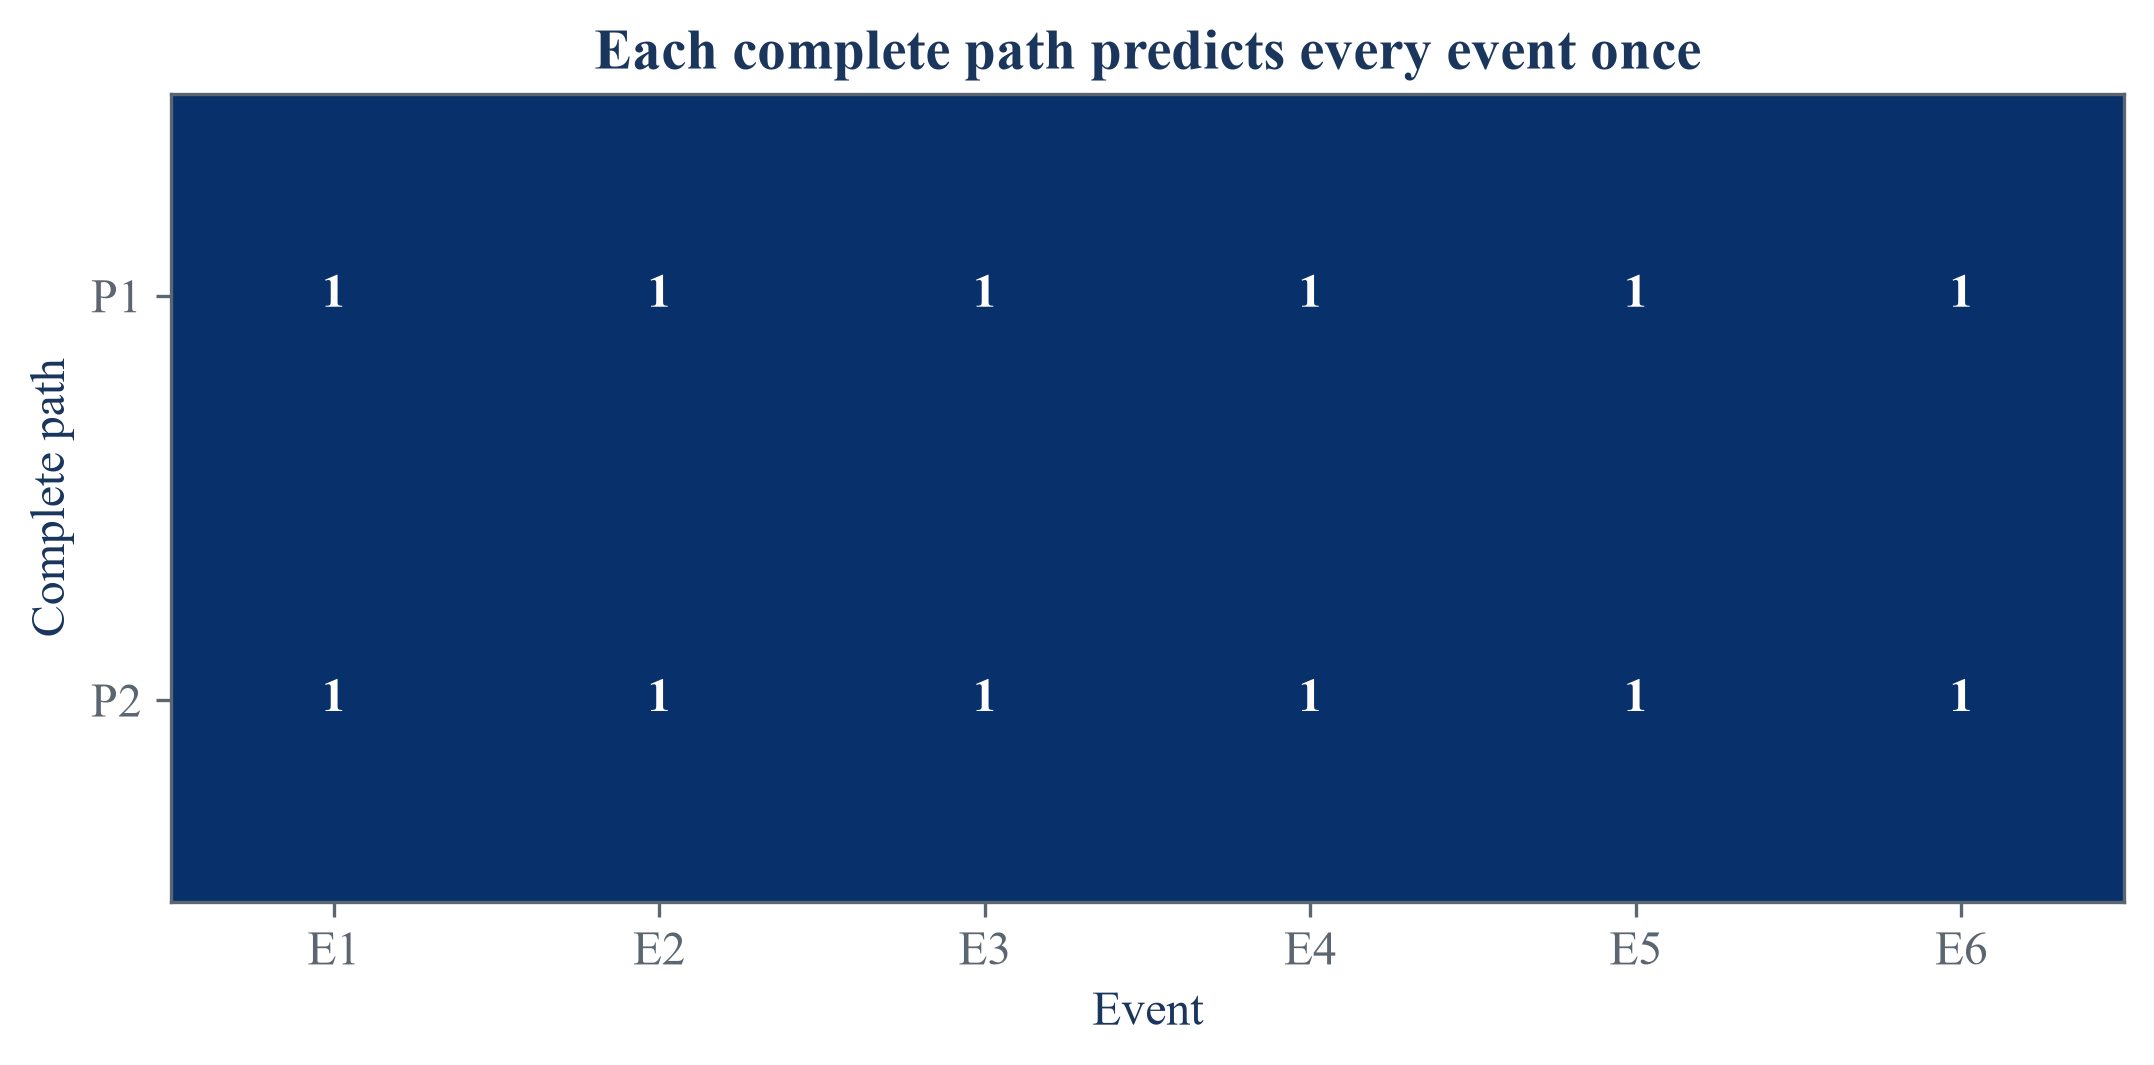

,Declared trial,Observations,Annual mean return,Annual volatility,Annual Sharpe ratio,Total return
0,Strategy A,752,0.085251,0.125153,0.681176,0.259942
1,Strategy B,752,-0.038353,0.125245,-0.306224,-0.128813
2,Strategy C,752,0.038353,0.125245,0.306224,0.095402


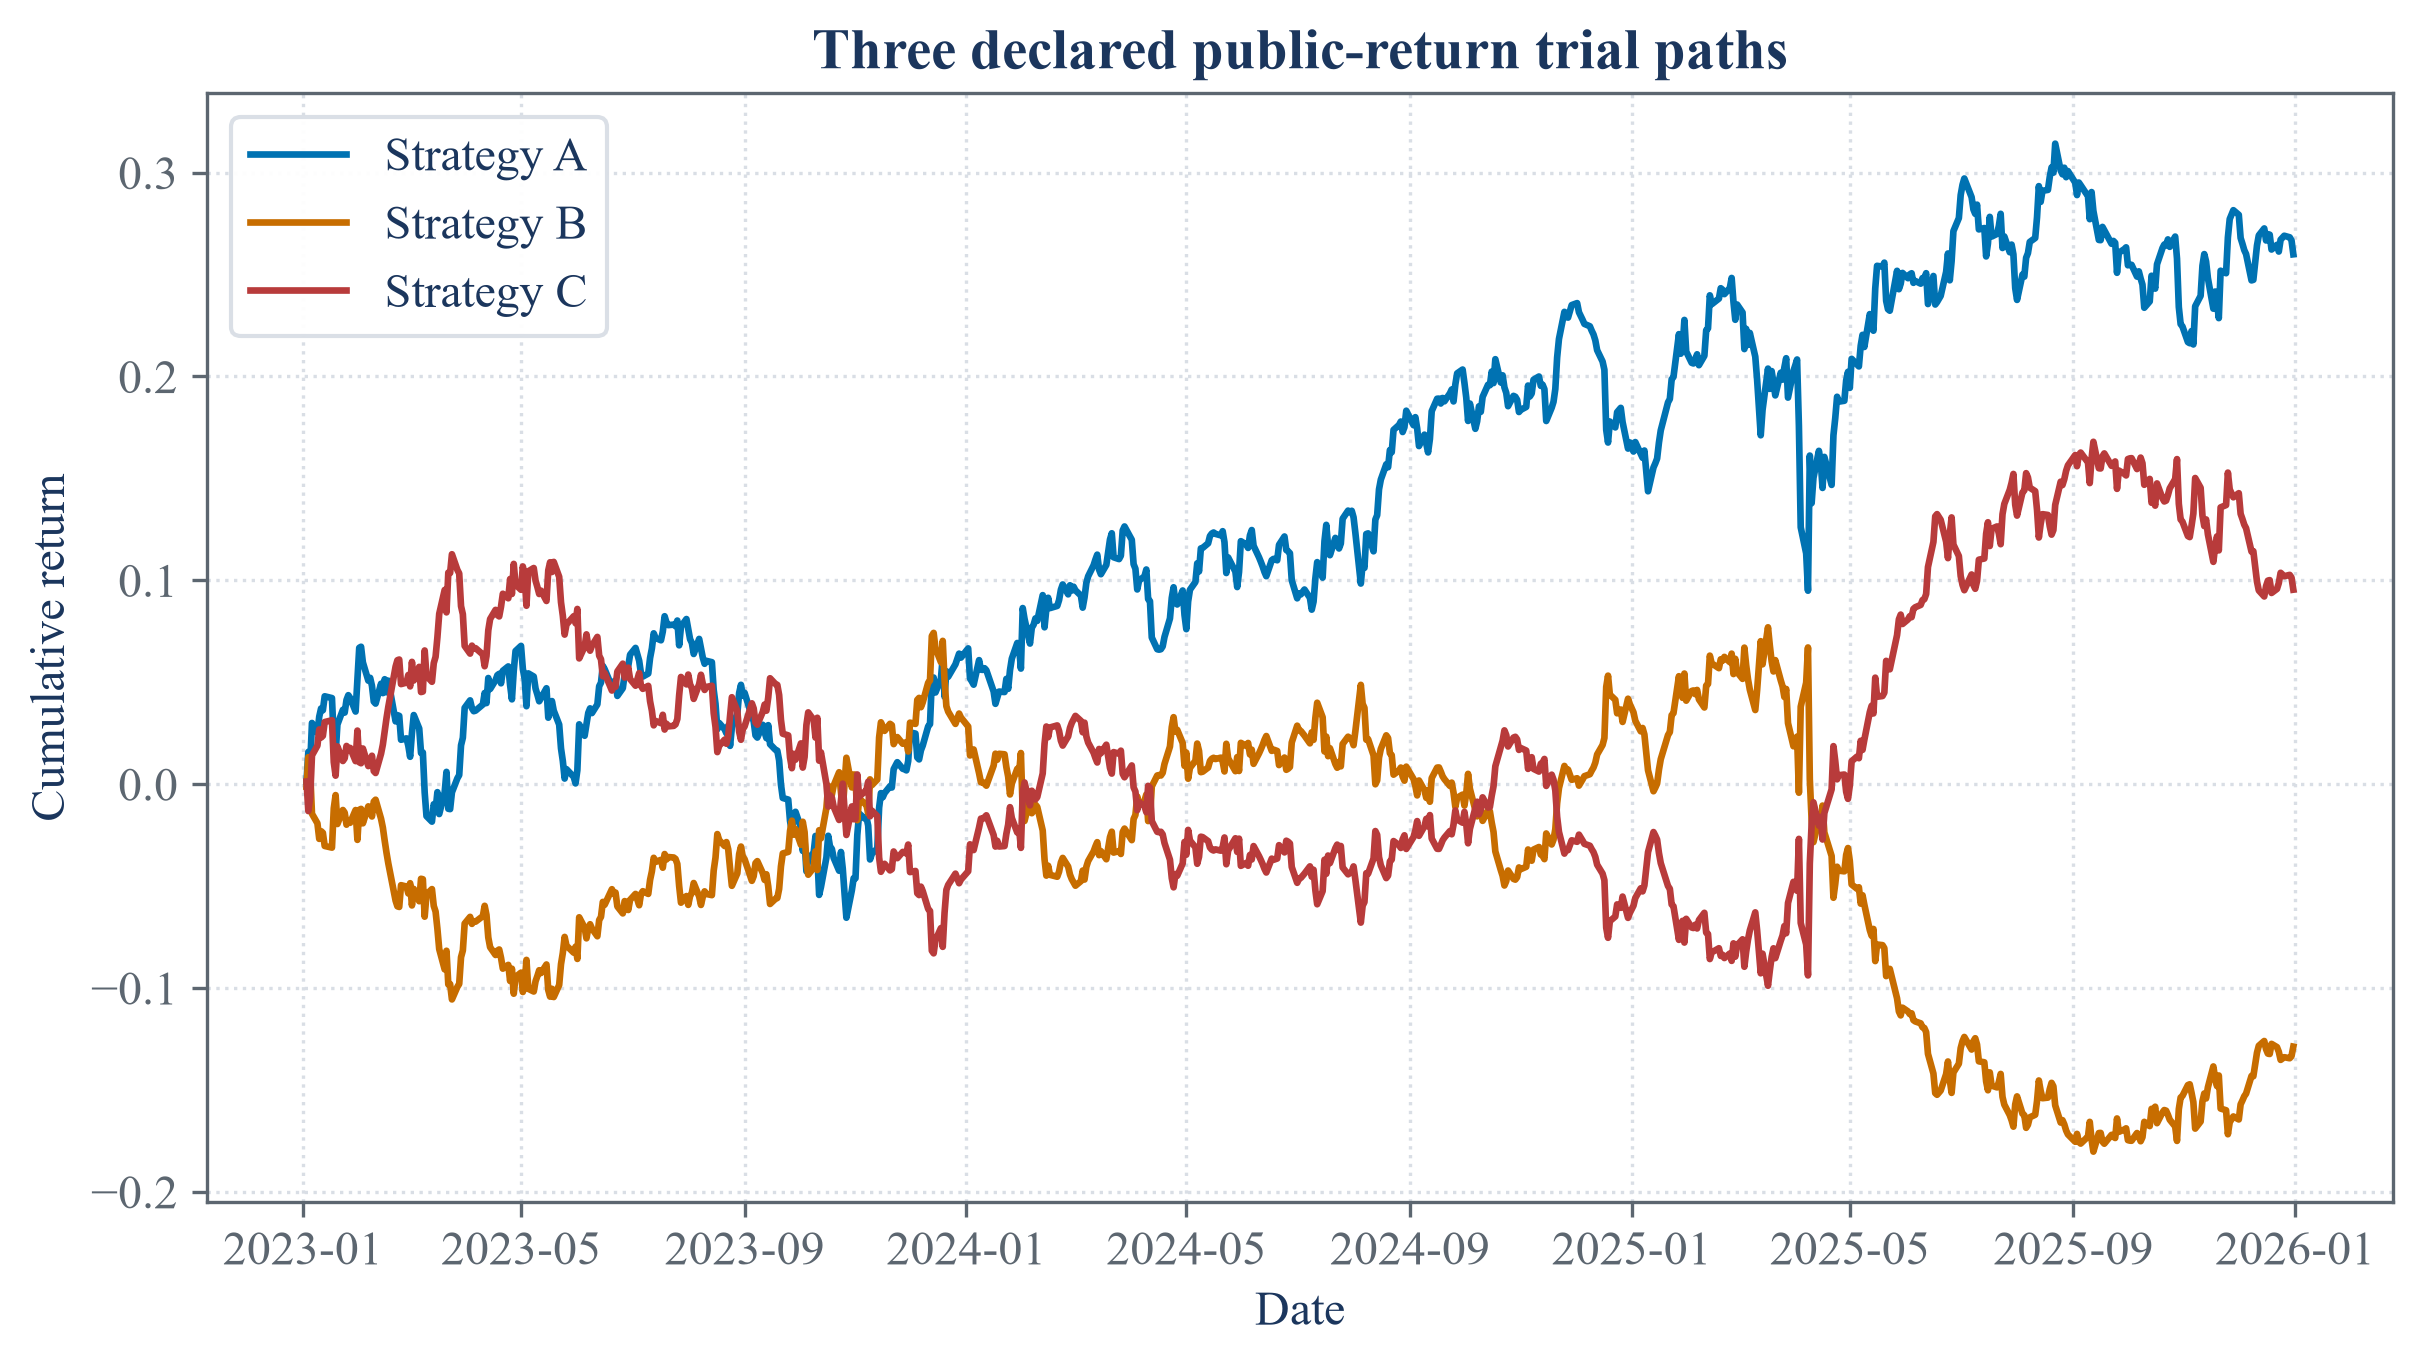

In [4]:
cpcv = report.backtest.validation
cpcv_rows = []
for fold in cpcv.folds:
    cpcv_rows.append({"Path": fold.path_id.upper(), "Fold": fold.fold_id.upper(), "Training events": len(fold.train_ids), "Test events": ", ".join(str(observation_ids.index(value) + 1) for value in fold.test_ids), "Refit record": fold.refit_id.upper()})
cpcv_table = pd.DataFrame(cpcv_rows)
save_table(cpcv_table, "protocol_cpcv_folds", "Combinatorial path contributions in the supplied record.", "tab:chapter28-cpcv-folds")
display(cpcv_table)

path_matrix = np.zeros((2, len(observation_ids)))
for row, path_id in enumerate(["p1", "p2"]):
    for fold in [value for value in cpcv.folds if value.path_id == path_id]:
        for observation_id in fold.test_ids:
            path_matrix[row, observation_ids.index(observation_id)] += 1
path_table = pd.DataFrame(path_matrix.astype(int), columns=[f"Event {index + 1}" for index in range(len(observation_ids))])
path_table.insert(0, "Path", ["P1", "P2"])
save_table(path_table, "protocol_cpcv_coverage", "Test contributions per event and complete path.", "tab:chapter28-cpcv-coverage")
display(path_table)

figure, axis = plt.subplots(figsize=(8.4, 3.5))
axis.imshow(path_matrix, cmap="Blues", vmin=0, vmax=1, aspect="auto")
axis.set_xticks(range(len(observation_ids)), [f"E{index + 1}" for index in range(len(observation_ids))])
axis.set_yticks([0, 1], ["P1", "P2"])
axis.set_xlabel("Event")
axis.set_ylabel("Complete path")
axis.set_title("Each complete path predicts every event once")
for row in range(path_matrix.shape[0]):
    for column in range(path_matrix.shape[1]):
        axis.text(column, row, str(int(path_matrix[row, column])), ha="center", va="center", color=palette["background"] if path_matrix[row, column] else palette["text"], fontweight="bold")
save_figure(figure, "protocol_cpcv_coverage")

trial_returns = public_trial_returns()
trial_summary = pd.DataFrame([{"Declared trial": column, "Observations": len(trial_returns), "Annual mean return": 252.0 * trial_returns[column].mean(), "Annual volatility": math.sqrt(252.0) * trial_returns[column].std(ddof=1), "Annual Sharpe ratio": math.sqrt(252.0) * trial_returns[column].mean() / trial_returns[column].std(ddof=1), "Total return": (1.0 + trial_returns[column]).prod() - 1.0} for column in trial_returns.columns])
save_table(trial_summary, "protocol_public_trial_paths", "Observed public-return paths for the declared three-trial family.", "tab:chapter28-public-trial-paths")
display(trial_summary)

figure, axis = plt.subplots(figsize=(9.4, 4.8))
for column, color in zip(trial_returns.columns, [palette["cyan"], palette["amber"], palette["rose"]]):
    axis.plot(trial_returns.index, (1.0 + trial_returns[column]).cumprod() - 1.0, color=color, linewidth=1.6, label=column)
axis.set_xlabel("Date")
axis.set_ylabel("Cumulative return")
axis.set_title("Three declared public-return trial paths")
axis.legend()
axis.grid(True)
save_figure(figure, "protocol_public_trial_paths")

## Recording rejected simulation evidence

A Monte Carlo backtest is interpretable only after its generation rule is stated:

$$
R_t=\mu+\sigma\varepsilon_t,
\qquad
\varepsilon_t\overset{\mathrm{iid}}{\sim}\mathcal N(0,1).
$$

Here, $R_t$ is a generated return at time $t$; $\mu$ is its supplied mean; $\sigma>0$ is its supplied standard deviation; $\varepsilon_t$ is a standard-normal shock; and iid means that the shocks are independent and identically distributed under the declared generation rule.

,Item,Value
0,Method,Monte Carlo
1,Declared trials,3
2,Temporal folds attached,No
3,Generation rule,"Gaussian returns with supplied mean, volatilit..."
4,Record accepted,Yes


,Case,Stage,Result,Message,Rejected
0,Fit membership differs from training,Stage 4,Rejected,Stage 4: every fold must refit on its complete...,True
1,Variable selection not refitted,Stage 4,Rejected,Stage 4: every fold must refit all required st...,True
2,Explanatory and predictive records merged,Stage 4,Rejected,Stage 4: explanatory and predictive evidence m...,True
3,Simple comparison record missing,Stage 4,Rejected,Stage 4: a naive benchmark identifier is required,True
4,Portfolio consideration omitted,Stage 5,Rejected,Stage 5: all source portfolio considerations a...,True
5,Transfer coefficient outside bounds,Stage 5,Rejected,Stage 5: transfer coefficient must be finite a...,True
6,Trial family changed,Stage 6,Rejected,Stage 6: trial-family identifier must match th...,True
7,Monte Carlo rule missing,Stage 6,Rejected,Stage 6: Monte Carlo requires an explicit DGP,True


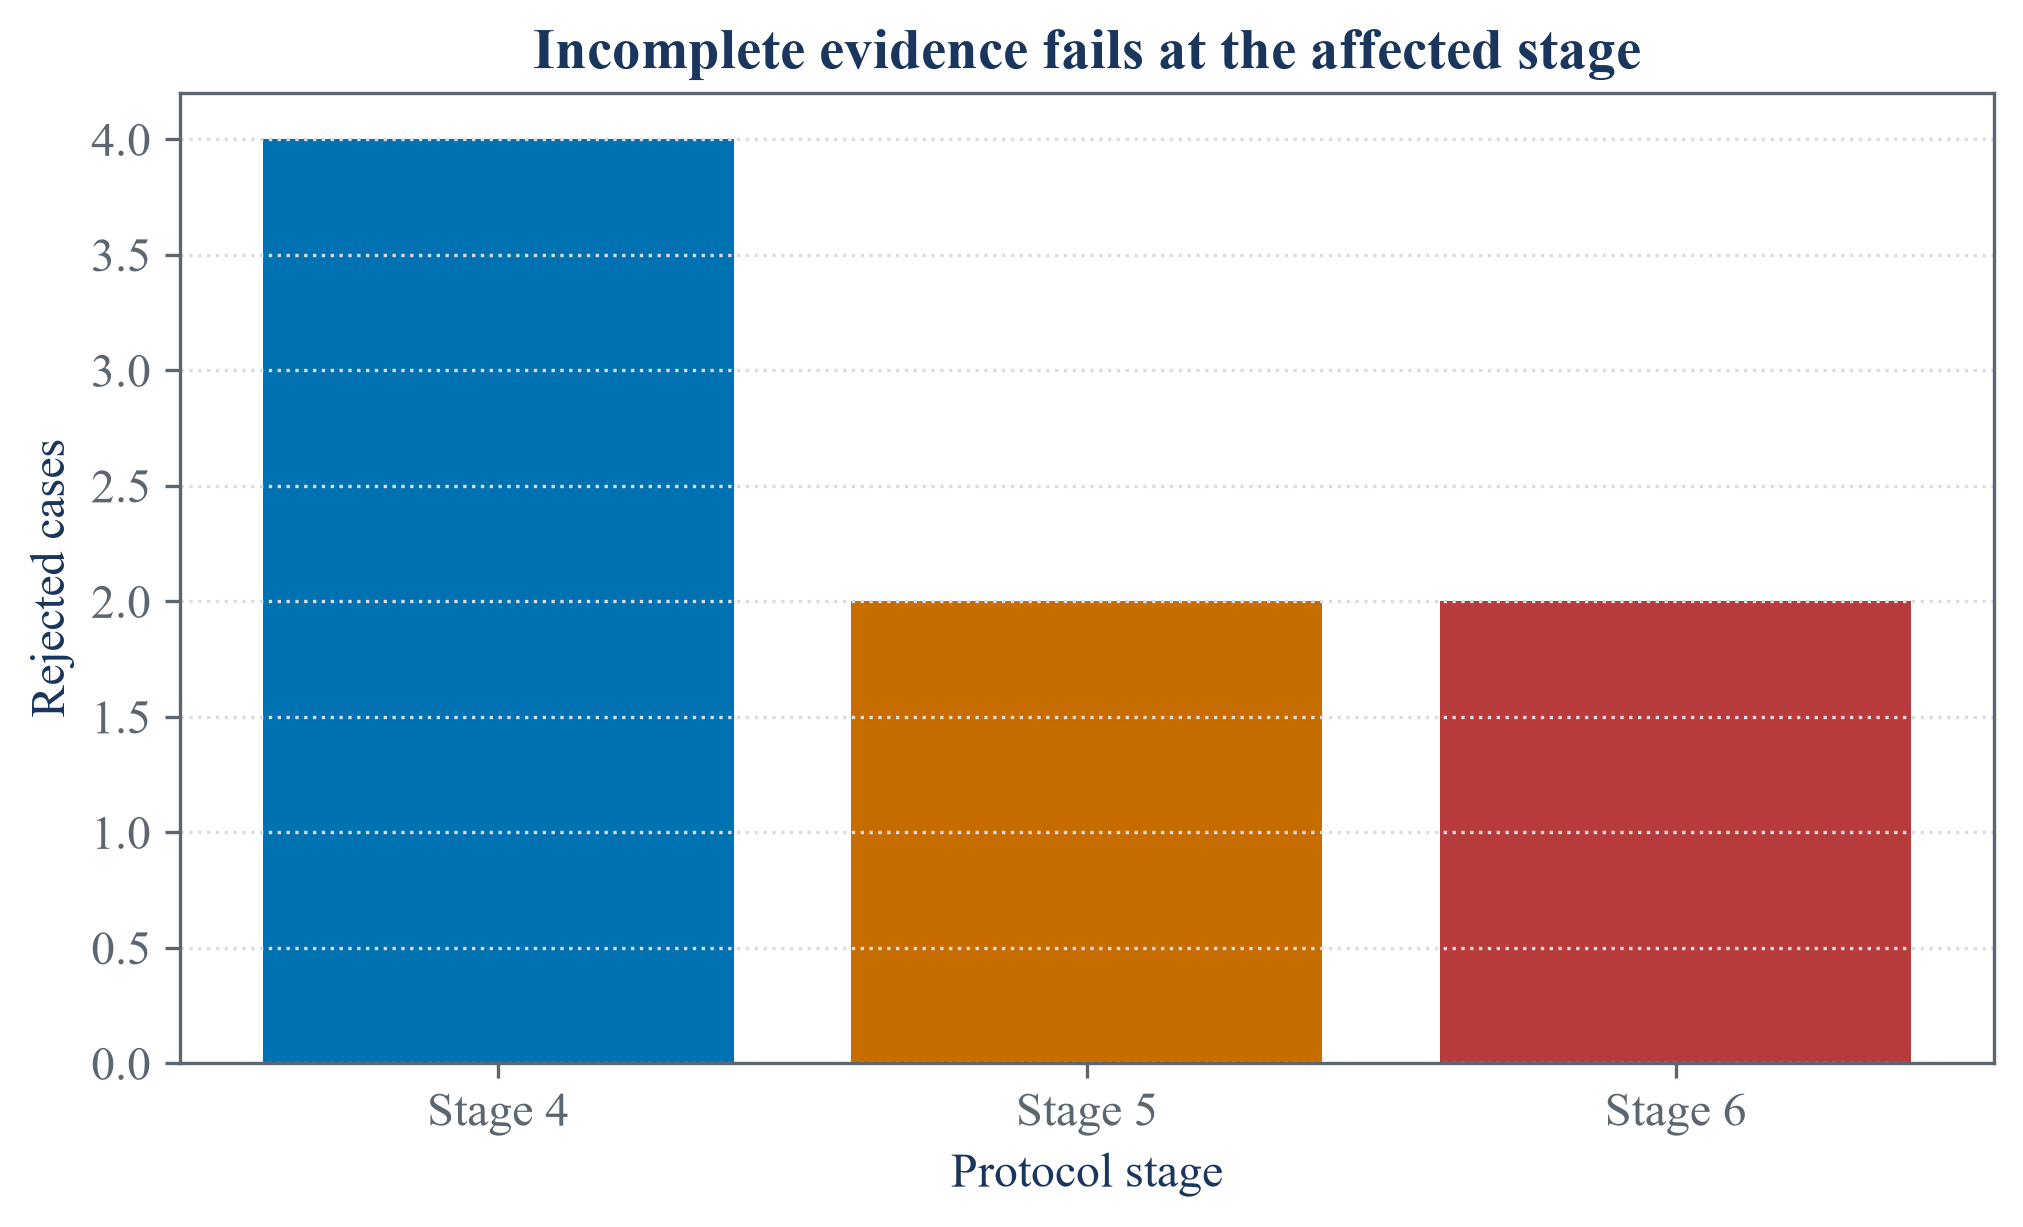

,Question,Evidence
0,Were fitting and prediction memberships separa...,"Training, fit, test, and prediction identifiers"
1,Were explanatory and predictive results separa...,Different measures and evidence records
2,Was the portfolio decision fully described?,Six required considerations and a bounded tran...
3,Does every temporal path refit the required pa...,Fold-specific refit records
4,Is a Monte Carlo backtest complete?,A stated generation rule and no incompatible t...


In [5]:
monte_carlo_stage = BacktestStage(method_labels=("MONTE_CARLO",), trial_family_id=report.trial_family_id, declared_trial_ids=report.declared_trial_ids, validation=None, monte_carlo_dgp="Gaussian returns with supplied mean, volatility, length, and random state")
monte_carlo_report = validate_causal_factor_protocol(replace(report, backtest=monte_carlo_stage))
monte_carlo_table = pd.DataFrame([{"Item": "Method", "Value": human_label(monte_carlo_stage.method_labels[0])}, {"Item": "Declared trials", "Value": len(monte_carlo_stage.declared_trial_ids)}, {"Item": "Temporal folds attached", "Value": "No"}, {"Item": "Generation rule", "Value": monte_carlo_stage.monte_carlo_dgp}, {"Item": "Record accepted", "Value": "Yes"}])
save_table(monte_carlo_table, "protocol_monte_carlo_record", "A complete Monte Carlo backtest declaration.", "tab:chapter28-monte-carlo-record")
display(monte_carlo_table)

invalid_rows = []
bad_fold = replace(validation.folds[0], fit_ids=validation.folds[0].test_ids)
bad_validation = replace(validation, folds=(bad_fold,) + validation.folds[1:])
invalid_rows.append(contract_case("Fit membership differs from training", "Stage 4", lambda: validate_causal_factor_protocol(replace(report, causal_explanatory_and_predictive_power=replace(report.causal_explanatory_and_predictive_power, validation=bad_validation)))))
missing_refit = replace(validation.folds[0], refit_components=("CAUSAL_ESTIMATION", "PORTFOLIO_CONSTRUCTION"))
invalid_rows.append(contract_case("Variable selection not refitted", "Stage 4", lambda: validate_causal_factor_protocol(replace(report, causal_explanatory_and_predictive_power=replace(report.causal_explanatory_and_predictive_power, validation=replace(validation, folds=(missing_refit,) + validation.folds[1:]))))))
invalid_rows.append(contract_case("Explanatory and predictive records merged", "Stage 4", lambda: validate_causal_factor_protocol(replace(report, causal_explanatory_and_predictive_power=replace(report.causal_explanatory_and_predictive_power, predictive_evidence_id=report.causal_explanatory_and_predictive_power.explanatory_evidence_id)))))
invalid_rows.append(contract_case("Simple comparison record missing", "Stage 4", lambda: validate_causal_factor_protocol(replace(report, causal_explanatory_and_predictive_power=replace(report.causal_explanatory_and_predictive_power, naive_benchmark_id="")))))
invalid_rows.append(contract_case("Portfolio consideration omitted", "Stage 5", lambda: validate_causal_factor_protocol(replace(report, causal_portfolio_construction=replace(report.causal_portfolio_construction, method_labels=report.causal_portfolio_construction.method_labels[:-1])))))
invalid_rows.append(contract_case("Transfer coefficient outside bounds", "Stage 5", lambda: validate_causal_factor_protocol(replace(report, causal_portfolio_construction=replace(report.causal_portfolio_construction, transfer_coefficient=1.2)))))
invalid_rows.append(contract_case("Trial family changed", "Stage 6", lambda: validate_causal_factor_protocol(replace(report, backtest=replace(report.backtest, trial_family_id="different-family")))))
invalid_rows.append(contract_case("Monte Carlo rule missing", "Stage 6", lambda: validate_causal_factor_protocol(replace(report, backtest=replace(monte_carlo_stage, monte_carlo_dgp="")))))
invalid_table = pd.DataFrame(invalid_rows)
invalid_table["Message"] = invalid_table["Message"].str.replace("pipeline components", "study components", regex=False)
save_table(invalid_table, "protocol_stage456_rejections", "Incomplete Stage 4, Stage 5, and Stage 6 records rejected by the released checks.", "tab:chapter28-stage456-rejections")
display(invalid_table)

invalid_counts = invalid_table.groupby("Stage")["Rejected"].sum().reset_index(name="Rejected cases")
figure, axis = plt.subplots(figsize=(7.8, 4.2))
axis.bar(invalid_counts["Stage"], invalid_counts["Rejected cases"], color=[palette["cyan"], palette["amber"], palette["rose"]])
axis.set_xlabel("Protocol stage")
axis.set_ylabel("Rejected cases")
axis.set_title("Incomplete evidence fails at the affected stage")
axis.grid(True, axis="y")
save_figure(figure, "protocol_stage456_rejections")

section_summary = pd.DataFrame([{"Question": "Were fitting and prediction memberships separated?", "Evidence": "Training, fit, test, and prediction identifiers"}, {"Question": "Were explanatory and predictive results separated?", "Evidence": "Different measures and evidence records"}, {"Question": "Was the portfolio decision fully described?", "Evidence": "Six required considerations and a bounded transfer coefficient"}, {"Question": "Does every temporal path refit the required parts?", "Evidence": "Fold-specific refit records"}, {"Question": "Is a Monte Carlo backtest complete?", "Evidence": "A stated generation rule and no incompatible temporal folds"}])
save_table(section_summary, "protocol_section2_summary", "Questions answered by Stages 4 through 6.", "tab:chapter28-section2-summary")
display(section_summary)

## Tests

In [6]:
assert fold_evidence["Fit equals training"].all()
assert fold_evidence["Predictions equal test"].all()
assert component_table["Recorded"].all()
assert len(public_metrics) == 3
assert (public_metrics["Test mean squared error"] >= 0.0).all()
assert (public_metrics["Simple-rule mean squared error"] >= 0.0).all()
assert np.isfinite(public_metrics["Test Spearman correlation"]).all()
assert len(prediction_frame) > 700
assert np.isfinite(strategy_summary.select_dtypes(include=[np.number]).to_numpy()).all()
assert transfer_table["Transfer coefficient"].between(-1.0, 1.0).all()
assert transfer_table.loc[transfer_table["Disturbance scale"] == 0.0, "Transfer coefficient"].iloc[0] == 1.0
assert np.all(path_matrix == 1)
assert len(trial_summary) == 3
assert isinstance(monte_carlo_report.backtest, BacktestStage)
assert invalid_table["Rejected"].all()
for stem in ["protocol_fold_refits", "protocol_public_folds", "protocol_public_predictions", "protocol_public_strategy", "protocol_public_weights", "protocol_transfer_sensitivity", "protocol_cpcv_coverage", "protocol_public_trial_paths", "protocol_stage456_rejections"]:
    assert (FIGURES / f"{stem}.pdf").is_file()
for stem in ["protocol_fold_evidence", "protocol_fold_refits", "protocol_stage4_metrics", "protocol_public_fold_metrics", "protocol_public_data", "protocol_portfolio_requirements", "protocol_public_strategy", "protocol_public_weights", "protocol_transfer_sensitivity", "protocol_cpcv_folds", "protocol_cpcv_coverage", "protocol_public_trial_paths", "protocol_monte_carlo_record", "protocol_stage456_rejections", "protocol_section2_summary"]:
    assert (TABLES / f"{stem}.tex").is_file()